# 💳 Credit Risk Modeling & Default Probability Scorecard

## Executive Summary & Project Architecture
In modern retail banking and fintech lending, assessing the creditworthiness of loan applicants is critical to minimizing Non-Performing Assets (NPAs) while expanding credit access.

This project builds an end-to-end Machine Learning pipeline to predict loan default probability and establish a credit risk assessment scorecard.

### Pipeline Workflow:
1. **Data Ingestion & Integration**: Joining bureau records, customer demographics, and loan transaction data.
2. **Data Cleaning & Anomaly Detection**: Imputing missing values, handling categorical inconsistencies, and outlier filtering.
3. **Exploratory Data Analysis (EDA)**: Investigating continuous distributions, class imbalance, and cross-tabulating default rates.
4. **Domain Feature Engineering**: Formulating credit risk ratios including Loan-to-Income (LTI), Delinquency Ratio, Average DPD, and Credit Utilization per Income.
5. **Feature Scaling & Multicollinearity Filtering (VIF)**: Applying `MinMaxScaler` and removing high-VIF variables.
6. **Information Value (IV) & Weight of Evidence (WoE)**: Identifying statistically predictive features ($IV > 0.02$) following regulatory scorecard standards.
7. **Class Imbalance Mitigation**: Addressing severe class imbalance using Random Under-Sampling and SMOTE-Tomek links.
8. **Model Optimization**: Hyperparameter tuning across Logistic Regression and XGBoost via Optuna, Bayesian Optimization, and GridSearchCV.
9. **Performance Evaluation**: Analyzing AUC-ROC, Gini Coefficient ($2 \times AUC - 1$), and Precision-Recall tradeoffs.
10. **Model Serialization**: Packaging the best model, scaler, and metadata into artifacts for production deployment.
---

## 1. Setup & Environment Initialization
Importing core computational libraries for numerical processing, data manipulation, statistical visualization, and machine learning modeling.

In [333]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))

## 2. Data Ingestion & Relational Merging
The raw dataset spans three relational tables:
* **`bureau_data.csv`**: Historical credit bureau data (open accounts, closed accounts, delinquency history, total DPD, credit utilization).
* **`customers.csv`**: Demographics (age, income, employment, dependants, residence type, address duration).
* **`loans.csv`**: Loan application parameters (purpose, loan type, sanction amount, tenure, balance) and target label (`default`).

Merging on primary key `cust_id` to assemble a unified customer profile.

In [334]:
df_bureau = pd.read_csv('dataset/bureau_data.csv')
df_customers = pd.read_csv('dataset/customers.csv')
df_loans = pd.read_csv('dataset/loans.csv')
df_bureau.shape, df_customers.shape, df_loans.shape

((50000, 8), (50000, 12), (50000, 15))

In [335]:
df_bureau.head(2)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4


In [336]:
df_customers.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


In [337]:
df_loans.head(2)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [338]:
df_merge = pd.merge(df_bureau,df_customers, on='cust_id')
df_merge.head(2)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,1,1,42,0,0,3,7,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,3,1,96,12,60,5,4,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


In [339]:
df = pd.merge(df_merge, df_loans, on='cust_id')
df.head()

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,1,1,42,0,0,3,7,44,M,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,3,1,96,12,60,5,4,38,M,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,2,1,82,24,147,6,58,46,F,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,3,0,115,15,87,5,26,55,F,...,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,4,2,120,0,0,5,10,37,M,...,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [340]:
df.shape

(50000, 33)

## 3. Stratified Train-Test Splitting & Missing Value Imputation
To strictly prevent data leakage, we perform a 70/30 train-test split immediately after merging before performing any feature imputation or scaling.

In [341]:
X = df.drop(columns=['default'])
y = df.default.astype(int)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [342]:
df_train = pd.concat([X_train,y_train],axis=1)
df_test = pd.concat([X_test,y_test],axis=1)

df_train.head()

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
38094,C38095,4,0,115,0,0,9,42,44,F,...,707000,14140.00,127260,565600,37,150837,117407,2023-05-15,2023-06-13,0
40624,C40625,2,2,87,0,0,7,8,39,M,...,4538000,90760.00,816840,3630400,21,3267359,3799236,2023-08-15,2023-08-22,0
49425,C49426,4,1,178,0,0,7,27,37,F,...,6011000,120220.00,1081980,4808800,27,2718477,1855781,2024-07-01,2024-07-05,0
35734,C35735,4,0,125,10,64,8,77,55,M,...,334000,6680.00,60120,267200,10,240479,250438,2023-02-17,2023-02-19,0
41708,C41709,3,1,132,0,0,6,85,46,M,...,418000,8360.00,75240,334400,28,200578,196396,2023-09-24,2023-10-24,0


In [343]:
df_train.columns

Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default'],
      dtype='object')

In [344]:
df_train.isna().sum()

cust_id                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utilization_ratio        0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 42
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_a

### Imputing Missing Values in `residence_type`
Checking missing values across columns. `residence_type` contains missing entries, which we impute using the training set mode.

In [345]:
train_mode = df_train.residence_type.mode()[0]
train_mode

'Owned'

In [346]:
train_mode = df_train.residence_type.mode()[0]
test_mode = df_test.residence_type.mode()[0]
df_train.residence_type.fillna(train_mode,inplace=True)
df_test.residence_type.fillna(test_mode,inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\1400420219.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train.residence_type.fillna(train_mode,inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\1400420219.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.



In [347]:
df_train.isna().sum()

cust_id                        0
number_of_open_accounts        0
number_of_closed_accounts      0
total_loan_months              0
delinquent_months              0
total_dpd                      0
enquiry_count                  0
credit_utilization_ratio       0
age                            0
gender                         0
marital_status                 0
employment_status              0
income                         0
number_of_dependants           0
residence_type                 0
years_at_current_address       0
city                           0
state                          0
zipcode                        0
loan_id                        0
loan_purpose                   0
loan_type                      0
sanction_amount                0
loan_amount                    0
processing_fee                 0
gst                            0
net_disbursement               0
loan_tenure_months             0
principal_outstanding          0
bank_balance_at_application    0
disbursal_

In [348]:
df_train.duplicated().sum()

np.int64(0)

In [349]:
df_train.describe()

,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,income,number_of_dependants,...,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default
count,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,...,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00,35000.00
mean,2.50,1.00,76.05,4.89,26.92,5.01,43.36,39.59,2636609.49,1.94,...,418905.43,4699666.66,3997926.26,80599.42,719626.73,3198341.01,25.90,1336119.06,988188.62,0.09
std,1.12,0.82,43.73,5.86,32.90,2.03,29.39,9.86,2623234.63,1.54,...,168888.38,6265691.05,5387224.00,120660.96,969700.32,4309779.20,12.43,1212376.27,1046263.95,0.28
min,1.00,0.00,1.00,0.00,0.00,1.00,0.00,18.00,0.00,0.00,...,110001.00,0.00,0.00,0.00,0.00,0.00,6.00,-1.00,0.00,0.00
25%,1.00,0.00,42.00,0.00,0.00,4.00,18.00,33.00,803000.00,0.00,...,302001.00,1135000.00,960000.00,19200.00,172800.00,768000.00,16.00,425519.00,286541.50,0.00
50%,2.00,1.00,71.00,3.00,14.00,5.00,39.00,40.00,1887000.00,2.00,...,400001.00,2652000.00,2236000.00,44740.00,402480.00,1788800.00,24.00,1002959.00,667902.50,0.00
75%,3.00,2.00,107.00,9.00,46.00,6.00,67.00,46.00,3334000.00,3.00,...,560001.00,5164000.00,4600000.00,92040.00,828000.00,3680000.00,35.00,1788849.25,1236398.75,0.00
max,4.00,2.00,223.00,24.00,171.00,9.00,99.00,70.00,11999000.00,5.00,...,700001.00,52175000.00,47667000.00,5698029.90,8580060.00,38133600.00,59.00,5000000.00,7846643.00,1.00


In [350]:
df_train.columns

Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default'],
      dtype='object')

## 4. Exploratory Data Analysis & Business Anomaly Filtering

### 4.1 Continuous Feature Distributions & Outlier Inspection
Partitioning features into continuous and categorical sets to analyze distribution skews, ranges, and outliers using horizontal boxplots and histograms.

In [351]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']


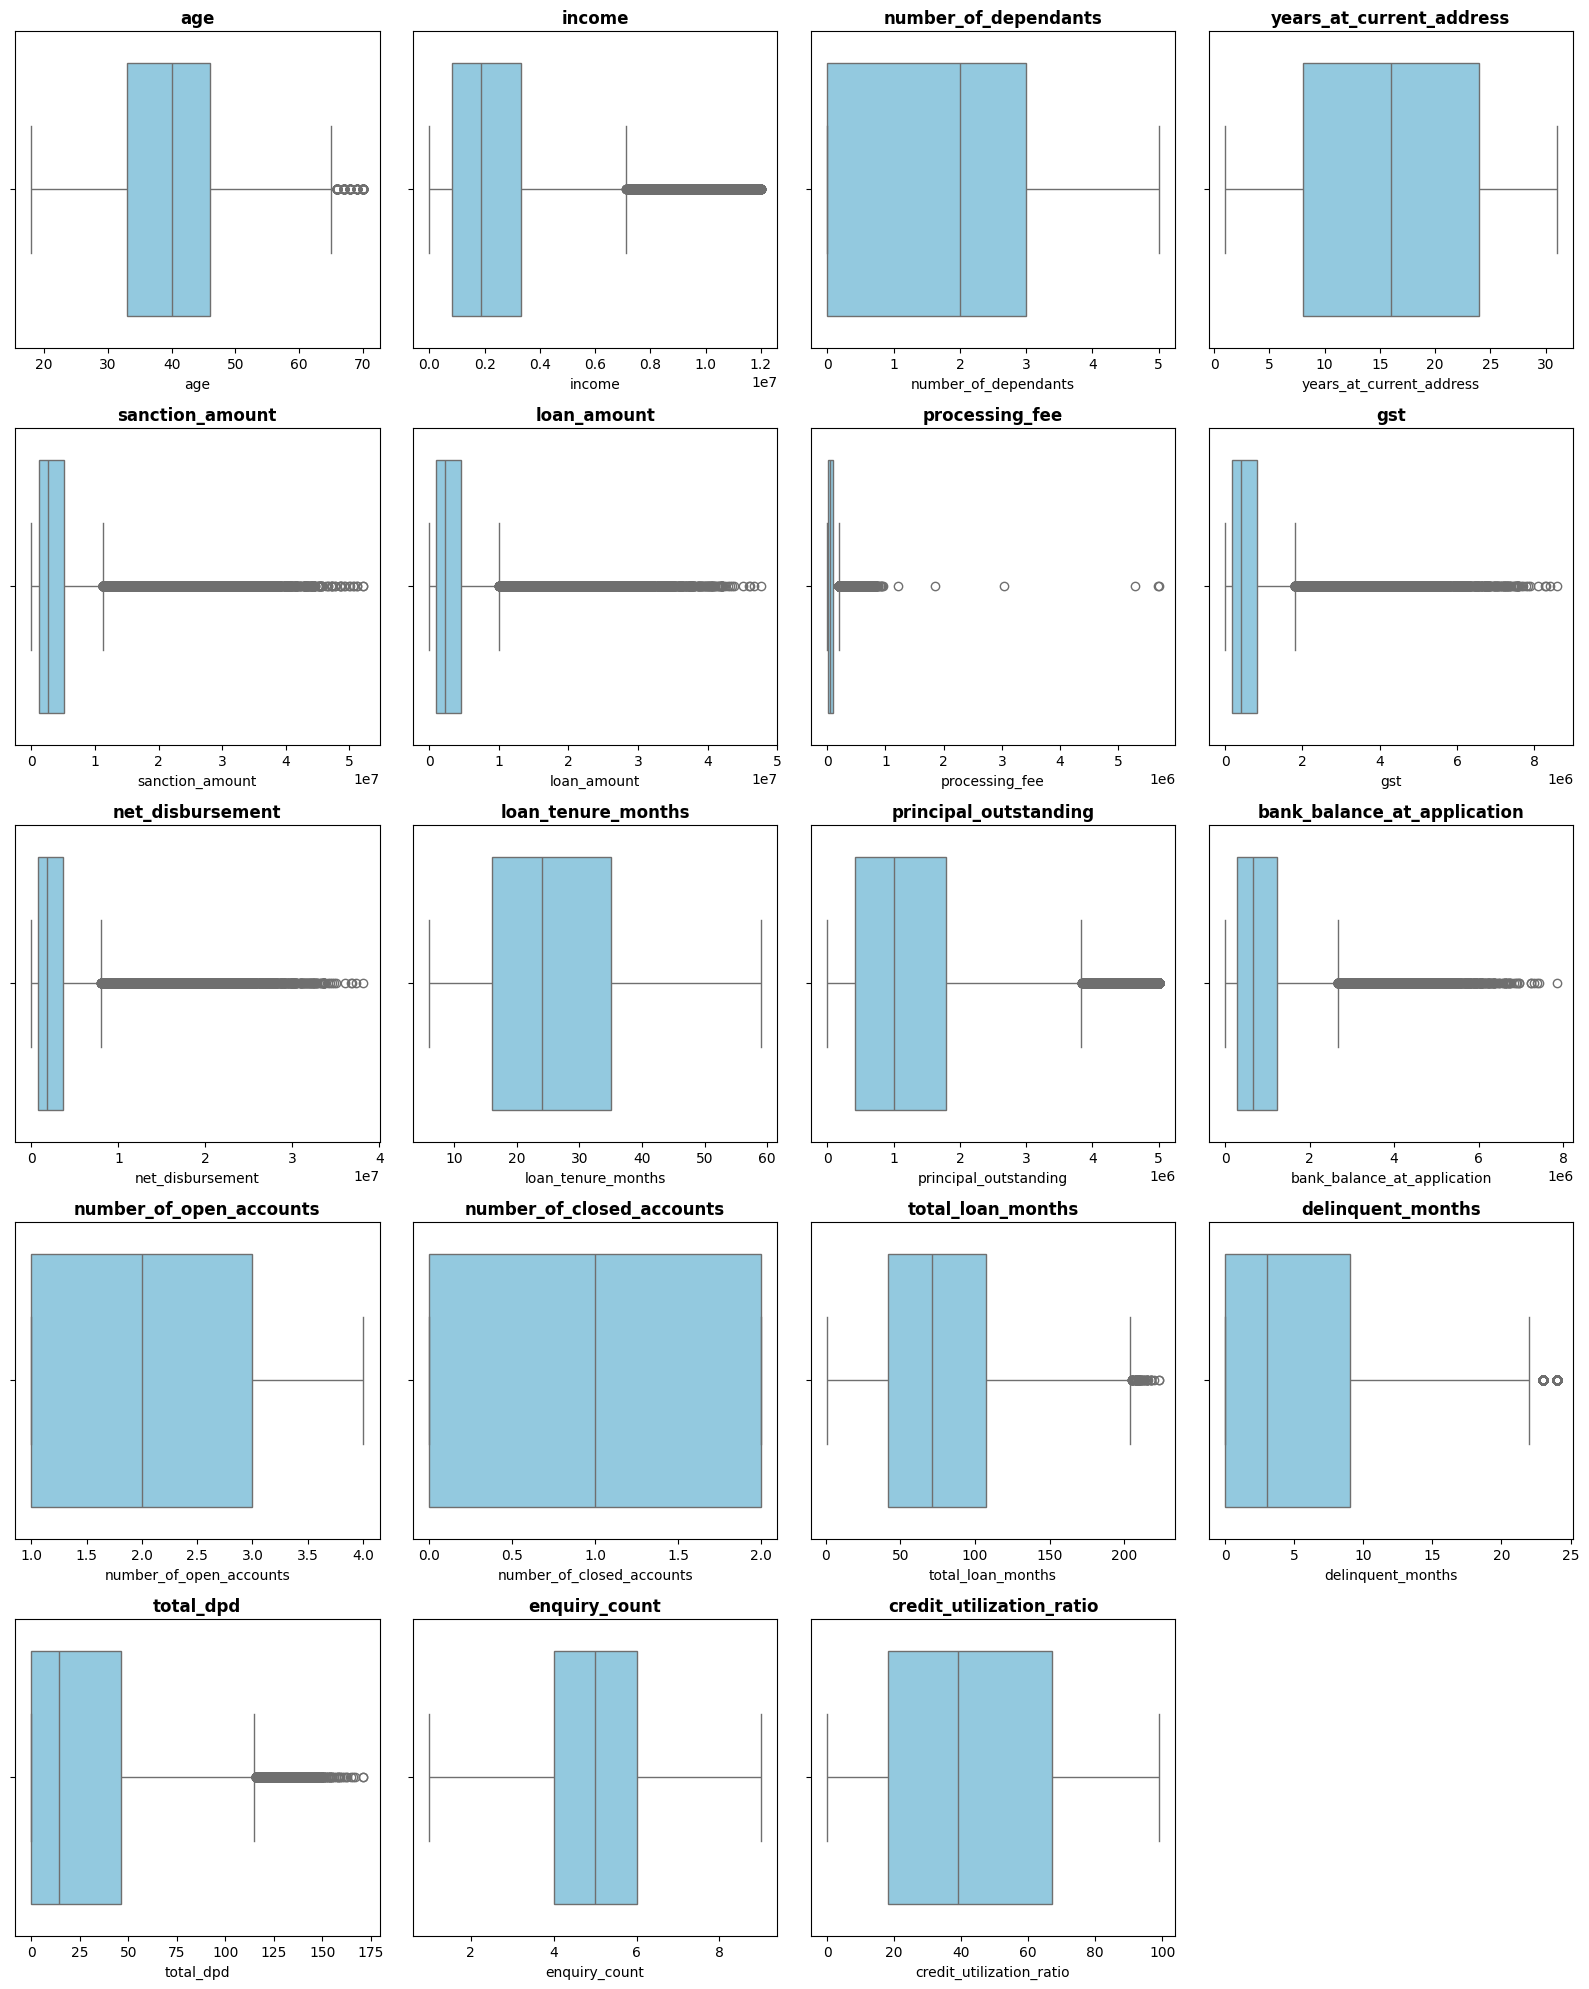

In [352]:
# Assuming df is your DataFrame and columns_continuous is your list of continuous columns
n_cols = 4
n_plots = len(columns_continuous)
n_rows = math.ceil(n_plots / n_cols)

# Create figure and subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

# Flatten axes array for easy 1D iteration
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Plot each continuous column
for idx, col in enumerate(columns_continuous):
    sns.boxplot(data=df_train[col], ax=axes[idx], color="skyblue",orient='h')
    axes[idx].set_title(col, fontsize=12, fontweight="bold")
    axes[idx].set_ylabel("")

# Remove any unused subplot axes in the grid
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

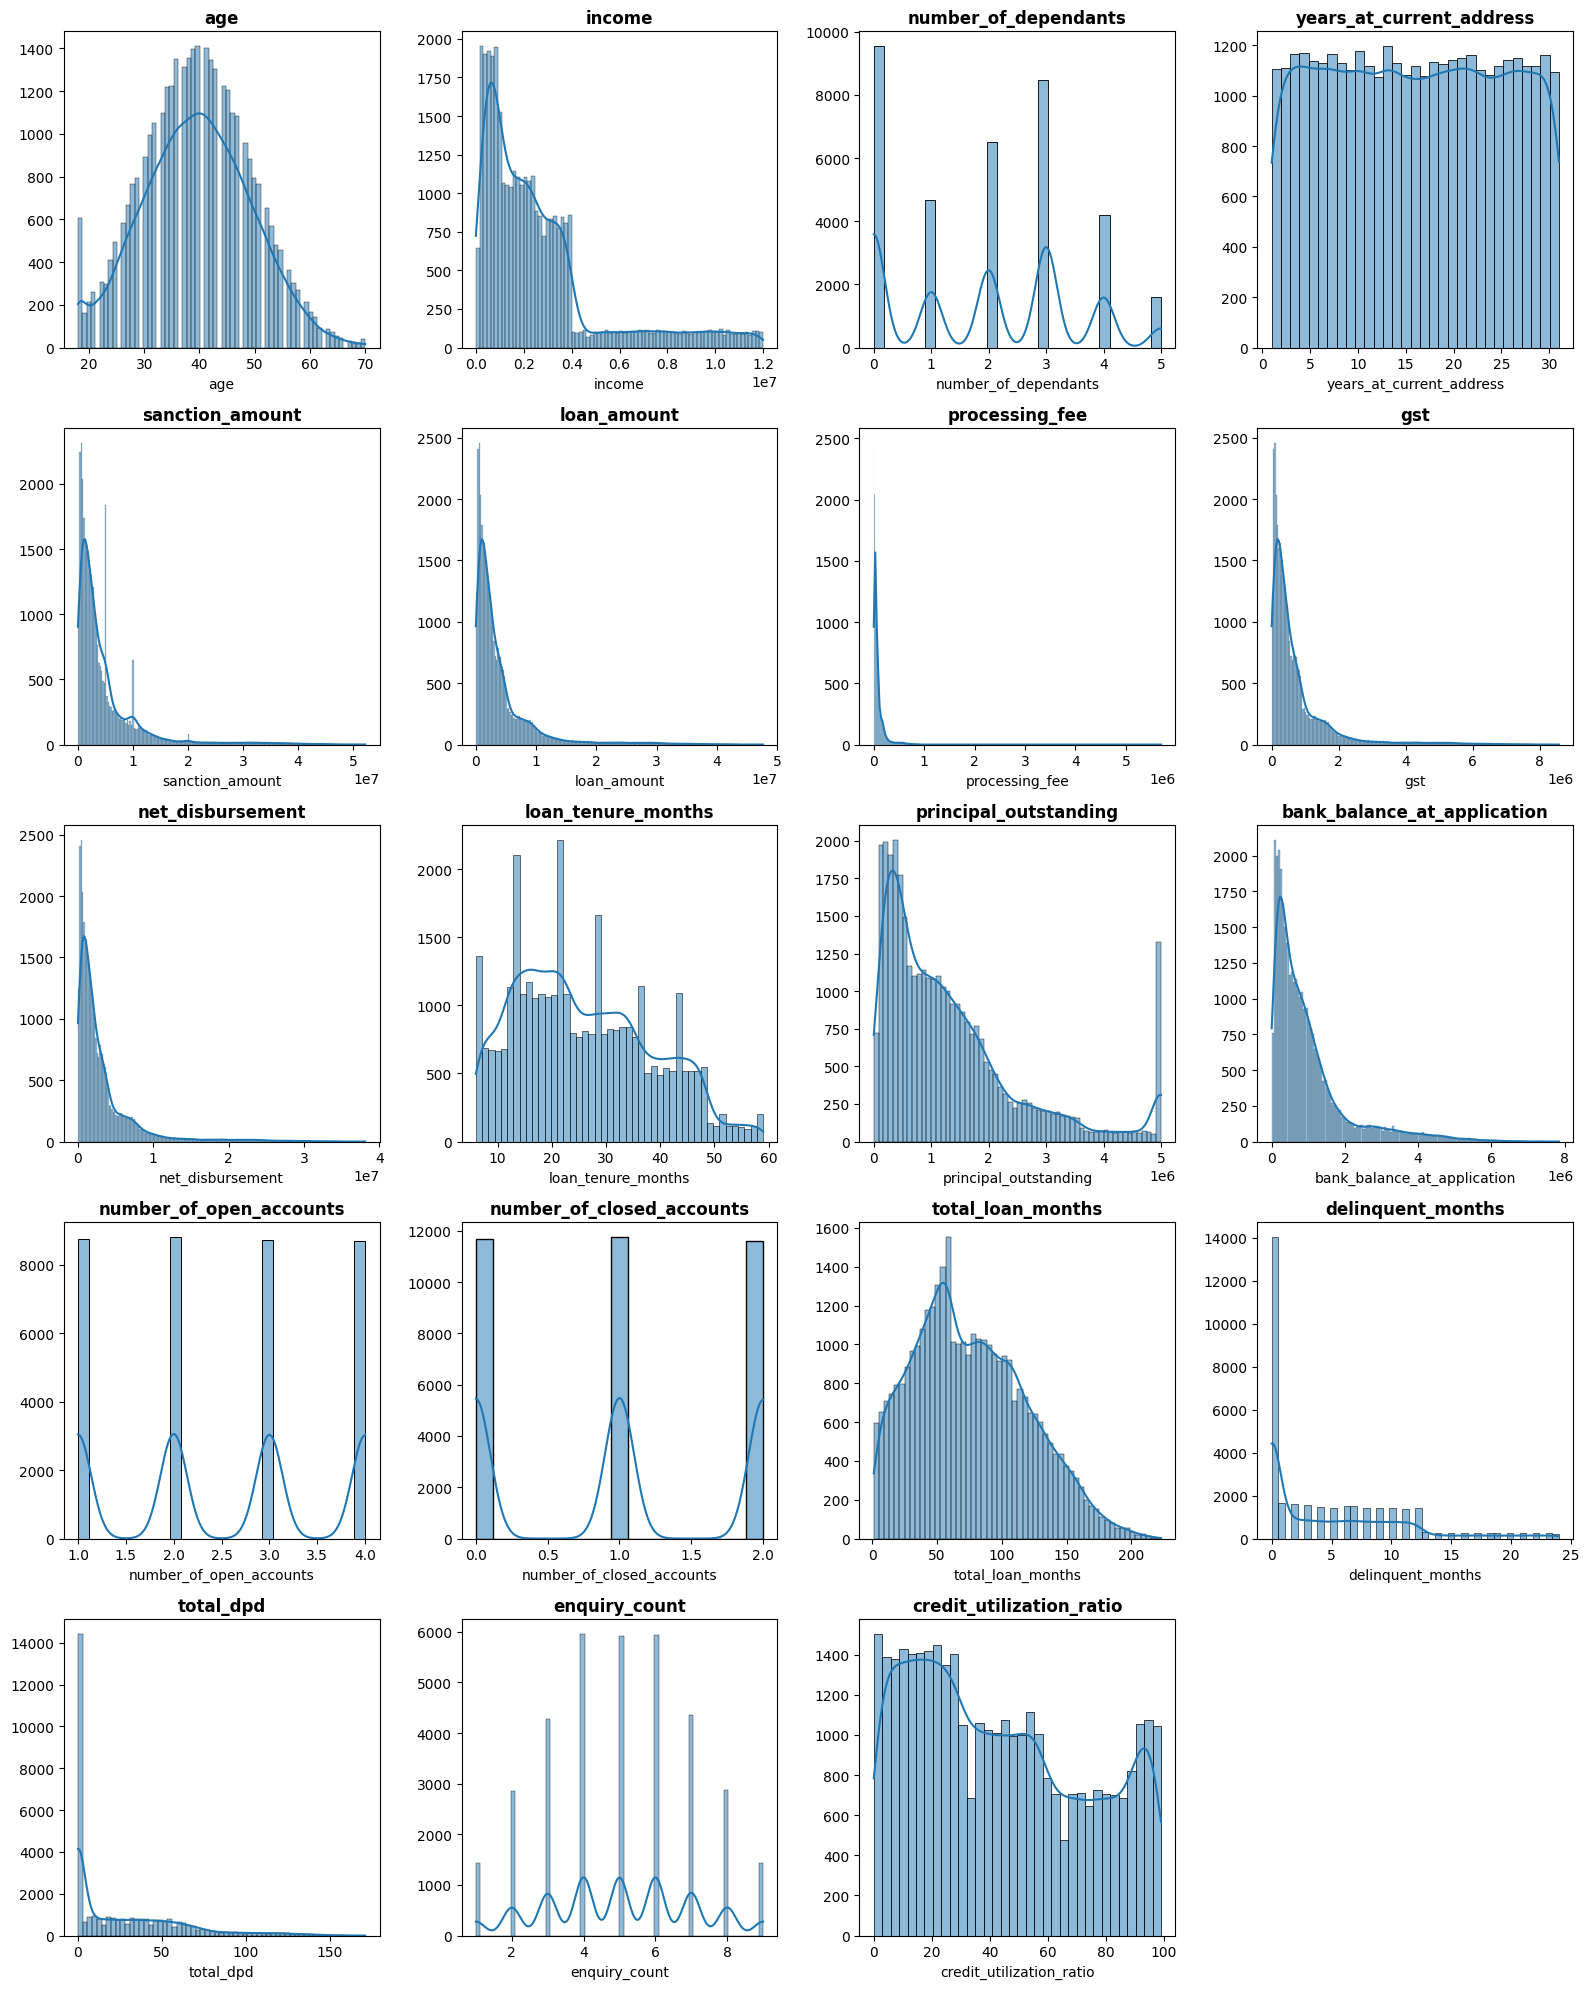

In [353]:
# Assuming df is your DataFrame and columns_continuous is your list of continuous columns
n_cols = 4
n_plots = len(columns_continuous)
n_rows = math.ceil(n_plots / n_cols)

# Create figure and subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

# Flatten axes array for easy 1D iteration
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Plot each continuous column
for idx, col in enumerate(columns_continuous):
    sns.histplot(data=df_train[col], ax=axes[idx], kde=True)
    axes[idx].set_title(col, fontsize=12, fontweight="bold")
    axes[idx].set_ylabel("")

# Remove any unused subplot axes in the grid
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 4.2 Business Rule Validation: Processing Fee Anomaly
Analyzing `processing_fee` relative to `loan_amount`. In compliant retail lending, processing fees rarely exceed 2-3% of the principal loan amount. We filter out anomalies where $\frac{\text{processing\_fee}}{\text{loan\_amount}} \ge 3\%$.

In [354]:
df_train.processing_fee.describe()

count     35000.00
mean      80599.42
std      120660.96
min           0.00
25%       19200.00
50%       44740.00
75%       92040.00
max     5698029.90
Name: processing_fee, dtype: float64

In [355]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['processing_fee','loan_amount']]

,processing_fee,loan_amount
9898,5293543.52,3626000
47089,1858964.77,1738000
33705,5678020.86,3812000
12294,5698029.90,4639000
28174,1214492.67,966000
29305,3036378.01,2616000


In [356]:
df_train_1 = df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()
df_train_1

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
38094,C38095,4,0,115,0,0,9,42,44,F,...,707000,14140.00,127260,565600,37,150837,117407,2023-05-15,2023-06-13,0
40624,C40625,2,2,87,0,0,7,8,39,M,...,4538000,90760.00,816840,3630400,21,3267359,3799236,2023-08-15,2023-08-22,0
49425,C49426,4,1,178,0,0,7,27,37,F,...,6011000,120220.00,1081980,4808800,27,2718477,1855781,2024-07-01,2024-07-05,0
35734,C35735,4,0,125,10,64,8,77,55,M,...,334000,6680.00,60120,267200,10,240479,250438,2023-02-17,2023-02-19,0
41708,C41709,3,1,132,0,0,6,85,46,M,...,418000,8360.00,75240,334400,28,200578,196396,2023-09-24,2023-10-24,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,C11285,4,1,129,23,126,7,93,33,F,...,4760000,95200.00,856800,3808000,19,2397863,1408084,2020-09-08,2020-09-17,1
44732,C44733,3,0,80,0,0,3,23,33,F,...,5302000,106040.00,954360,4241600,12,1676958,1215502,2024-01-12,2024-01-21,0
38158,C38159,1,2,8,0,0,2,53,35,M,...,6570000,131400.00,1182600,5256000,48,1497625,993374,2023-05-17,2023-06-14,0
860,C00861,3,1,130,5,24,7,17,42,F,...,3194000,63880.00,574920,2555200,22,1316297,672134,2019-08-25,2019-09-12,0


In [357]:
df_test = df_test[(df_test.processing_fee/df_test.loan_amount)<0.03].copy()
df_test.shape

(14997, 33)

In [358]:
df_train_1[(df_train_1.gst/df_train_1.loan_amount)>0.2][['gst','loan_amount']]

,gst,loan_amount


In [359]:
df_train_1[df_train_1.net_disbursement > df_train_1.loan_amount]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default


### 4.3 Categorical Feature Analysis & Typo Normalization
Cleaning categorical values (fixing typos like `'Personaal'` $\rightarrow$ `'Personal'`) and analyzing borrower distributions across categories segmented by loan default status.

In [360]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [361]:
for col in columns_categorical:
    print(f"{col} -> {df_train_1[col].unique()}")

gender -> ['F' 'M']
marital_status -> ['Single' 'Married']
employment_status -> ['Self-Employed' 'Salaried']
residence_type -> ['Mortgage' 'Owned' 'Rented']
city -> ['Chennai' 'Ahmedabad' 'Pune' 'Kolkata' 'Mumbai' 'Hyderabad' 'Jaipur'
 'Delhi' 'Lucknow' 'Bangalore']
state -> ['Tamil Nadu' 'Gujarat' 'Maharashtra' 'West Bengal' 'Telangana'
 'Rajasthan' 'Delhi' 'Uttar Pradesh' 'Karnataka']
zipcode -> [600001 380001 411001 700001 400001 500001 302001 110001 226001 560001]
loan_purpose -> ['Home' 'Personal' 'Auto' 'Education' 'Personaal']
loan_type -> ['Secured' 'Unsecured']
default -> [0 1]


In [362]:
df_train_1.loan_purpose.replace('Personaal','Personal',inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\115966562.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train_1.loan_purpose.replace('Personaal','Personal',inplace=True)


In [363]:
df_train_1.loan_purpose.unique()

array(['Home', 'Personal', 'Auto', 'Education'], dtype=object)

In [364]:
for col in columns_categorical:
    print(f"{col} -> {df_test[col].unique()}")

gender -> ['F' 'M']
marital_status -> ['Married' 'Single']
employment_status -> ['Self-Employed' 'Salaried']
residence_type -> ['Owned' 'Rented' 'Mortgage']
city -> ['Hyderabad' 'Jaipur' 'Delhi' 'Pune' 'Chennai' 'Ahmedabad' 'Lucknow'
 'Kolkata' 'Bangalore' 'Mumbai']
state -> ['Telangana' 'Rajasthan' 'Delhi' 'Maharashtra' 'Tamil Nadu' 'Gujarat'
 'Uttar Pradesh' 'West Bengal' 'Karnataka']
zipcode -> [500001 302001 110001 411001 600001 380001 226001 700001 560001 400001]
loan_purpose -> ['Education' 'Home' 'Auto' 'Personal' 'Personaal']
loan_type -> ['Secured' 'Unsecured']
default -> [0 1]


In [365]:
df_test.loan_purpose.replace('Personaal','Personal',inplace=True)
df_test.loan_purpose.unique()

C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\2055933137.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_test.loan_purpose.replace('Personaal','Personal',inplace=True)


array(['Education', 'Home', 'Auto', 'Personal'], dtype=object)

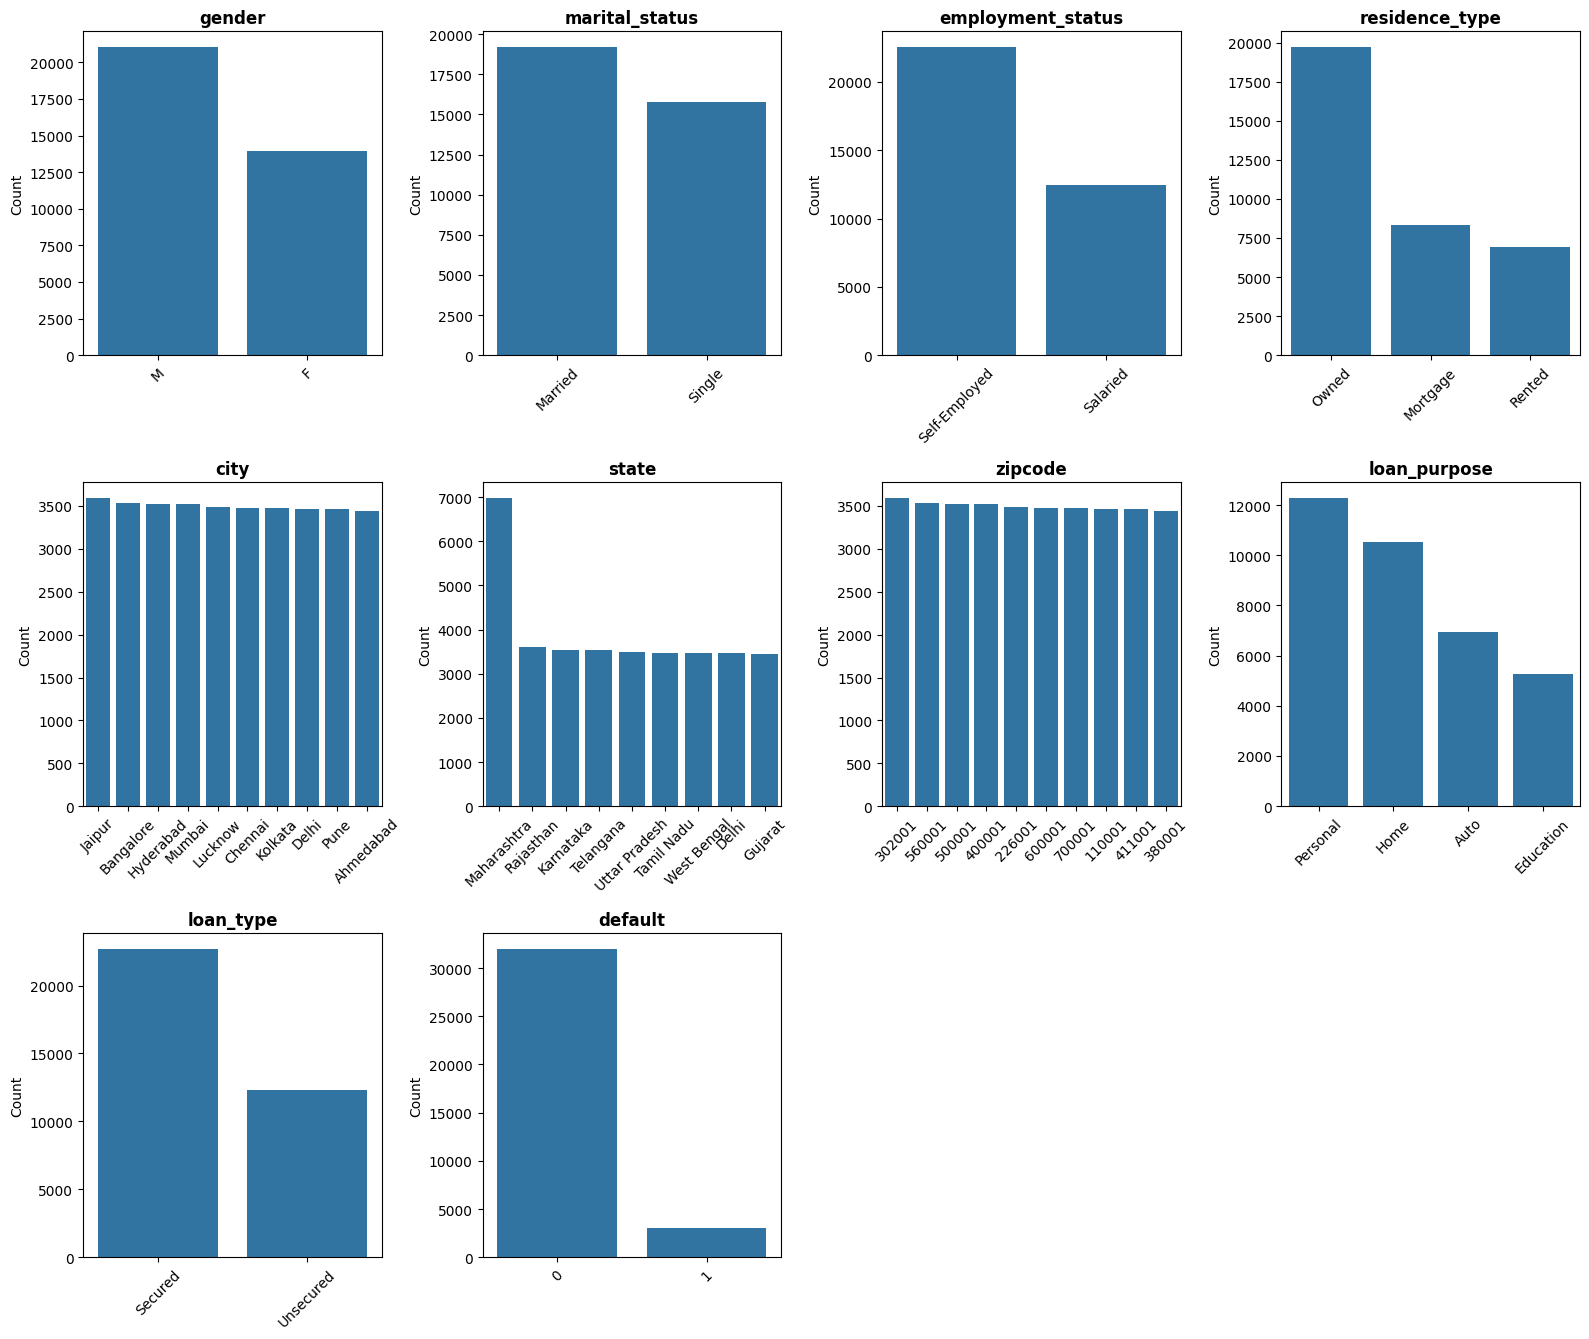

In [366]:
# Assuming df is your DataFrame and columns_categorical is your list of categorical columns
n_cols = 4
n_plots = len(columns_categorical)
n_rows = math.ceil(n_plots / n_cols)

# Create figure and subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows))

# Flatten axes array for simple indexing
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Plot each categorical column
for idx, col in enumerate(columns_categorical):
    # Order categories by frequency (descending)
    order = df_train_1[col].value_counts().index
    sns.countplot(data=df_train_1, x=col, order=order, ax=axes[idx])

    axes[idx].set_title(col, fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("Count")
    axes[idx].tick_params(axis="x", rotation=45)

# Remove unused axes
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

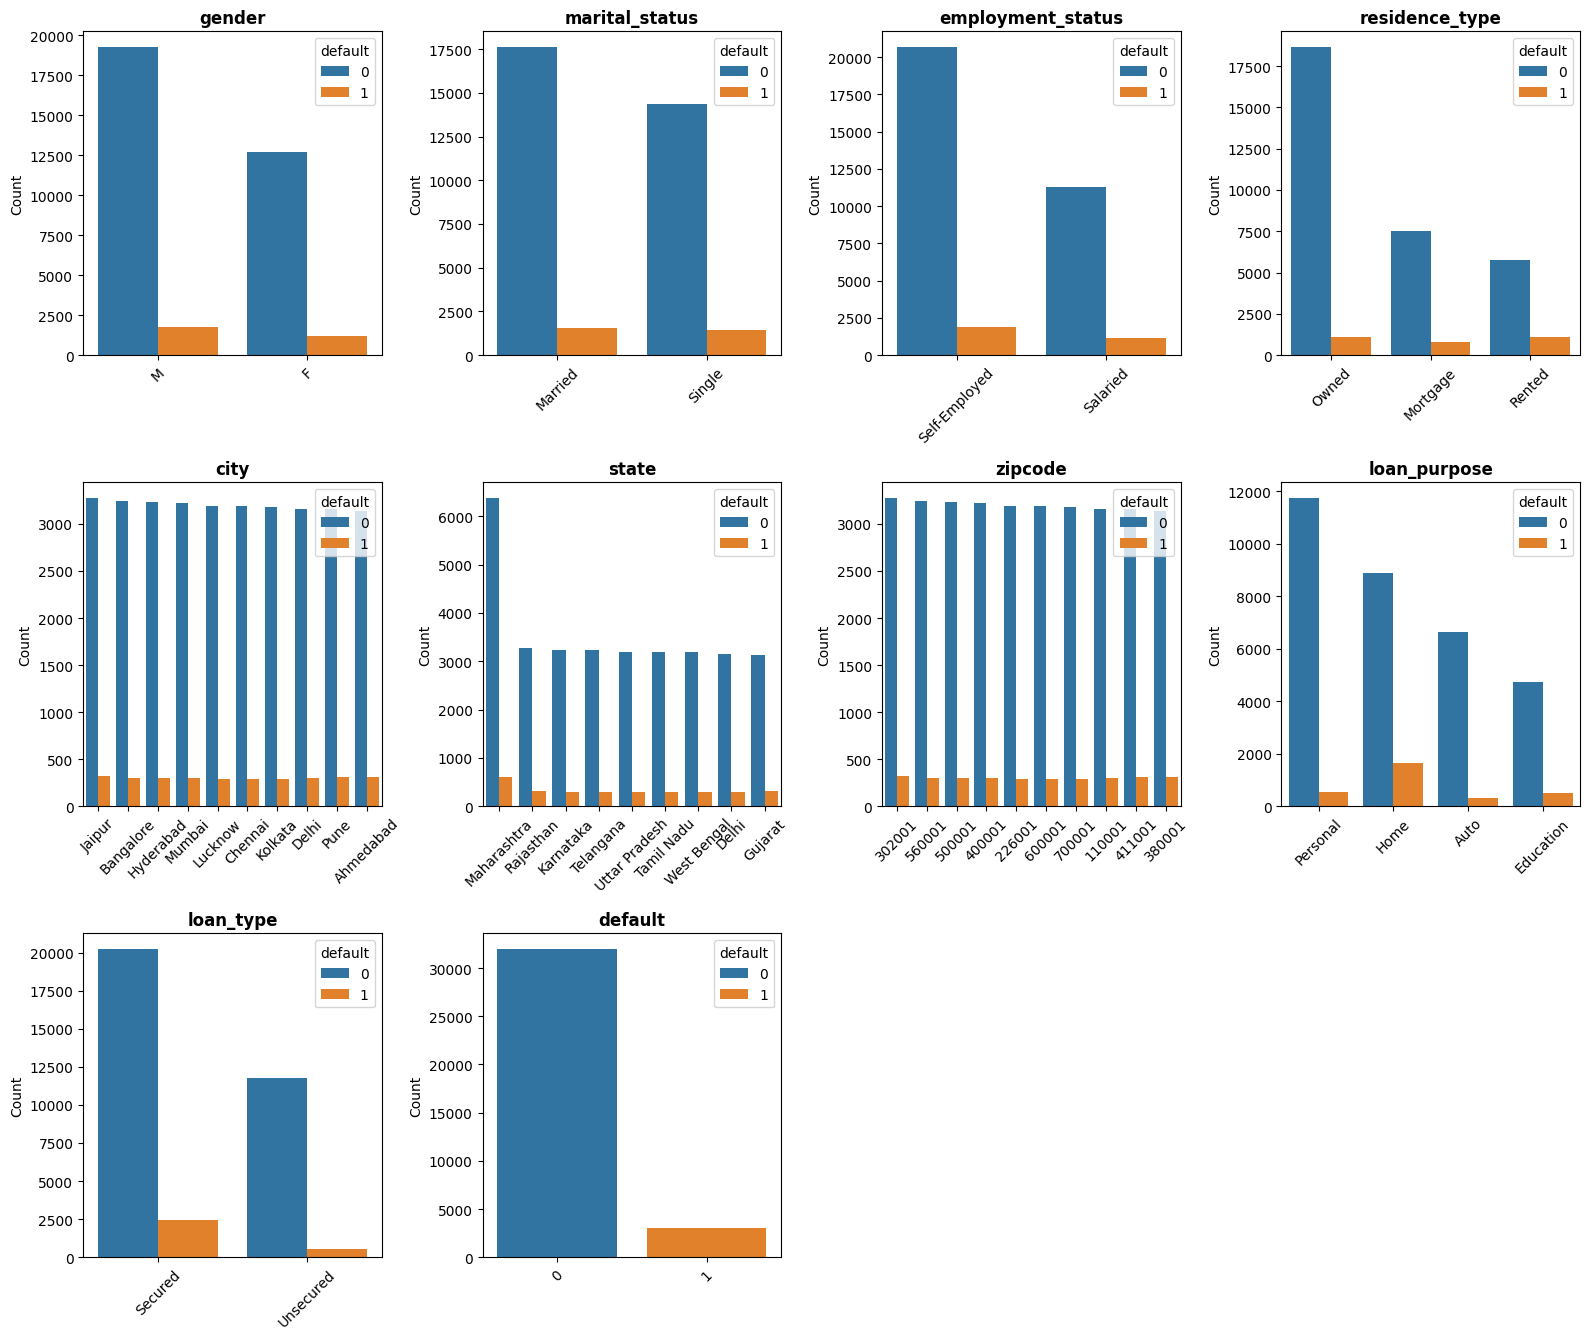

In [367]:
# Assuming df is your DataFrame and columns_categorical is your list of categorical columns
n_cols = 4
n_plots = len(columns_categorical)
n_rows = math.ceil(n_plots / n_cols)

# Create figure and subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows))

# Flatten axes array for simple indexing
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Plot each categorical column
for idx, col in enumerate(columns_categorical):
    # Order categories by frequency (descending)
    order = df_train_1[col].value_counts().index
    sns.countplot(data=df_train_1, x=col, order=order, hue='default' , ax=axes[idx])

    axes[idx].set_title(col, fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("Count")
    axes[idx].tick_params(axis="x", rotation=45)

# Remove unused axes
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

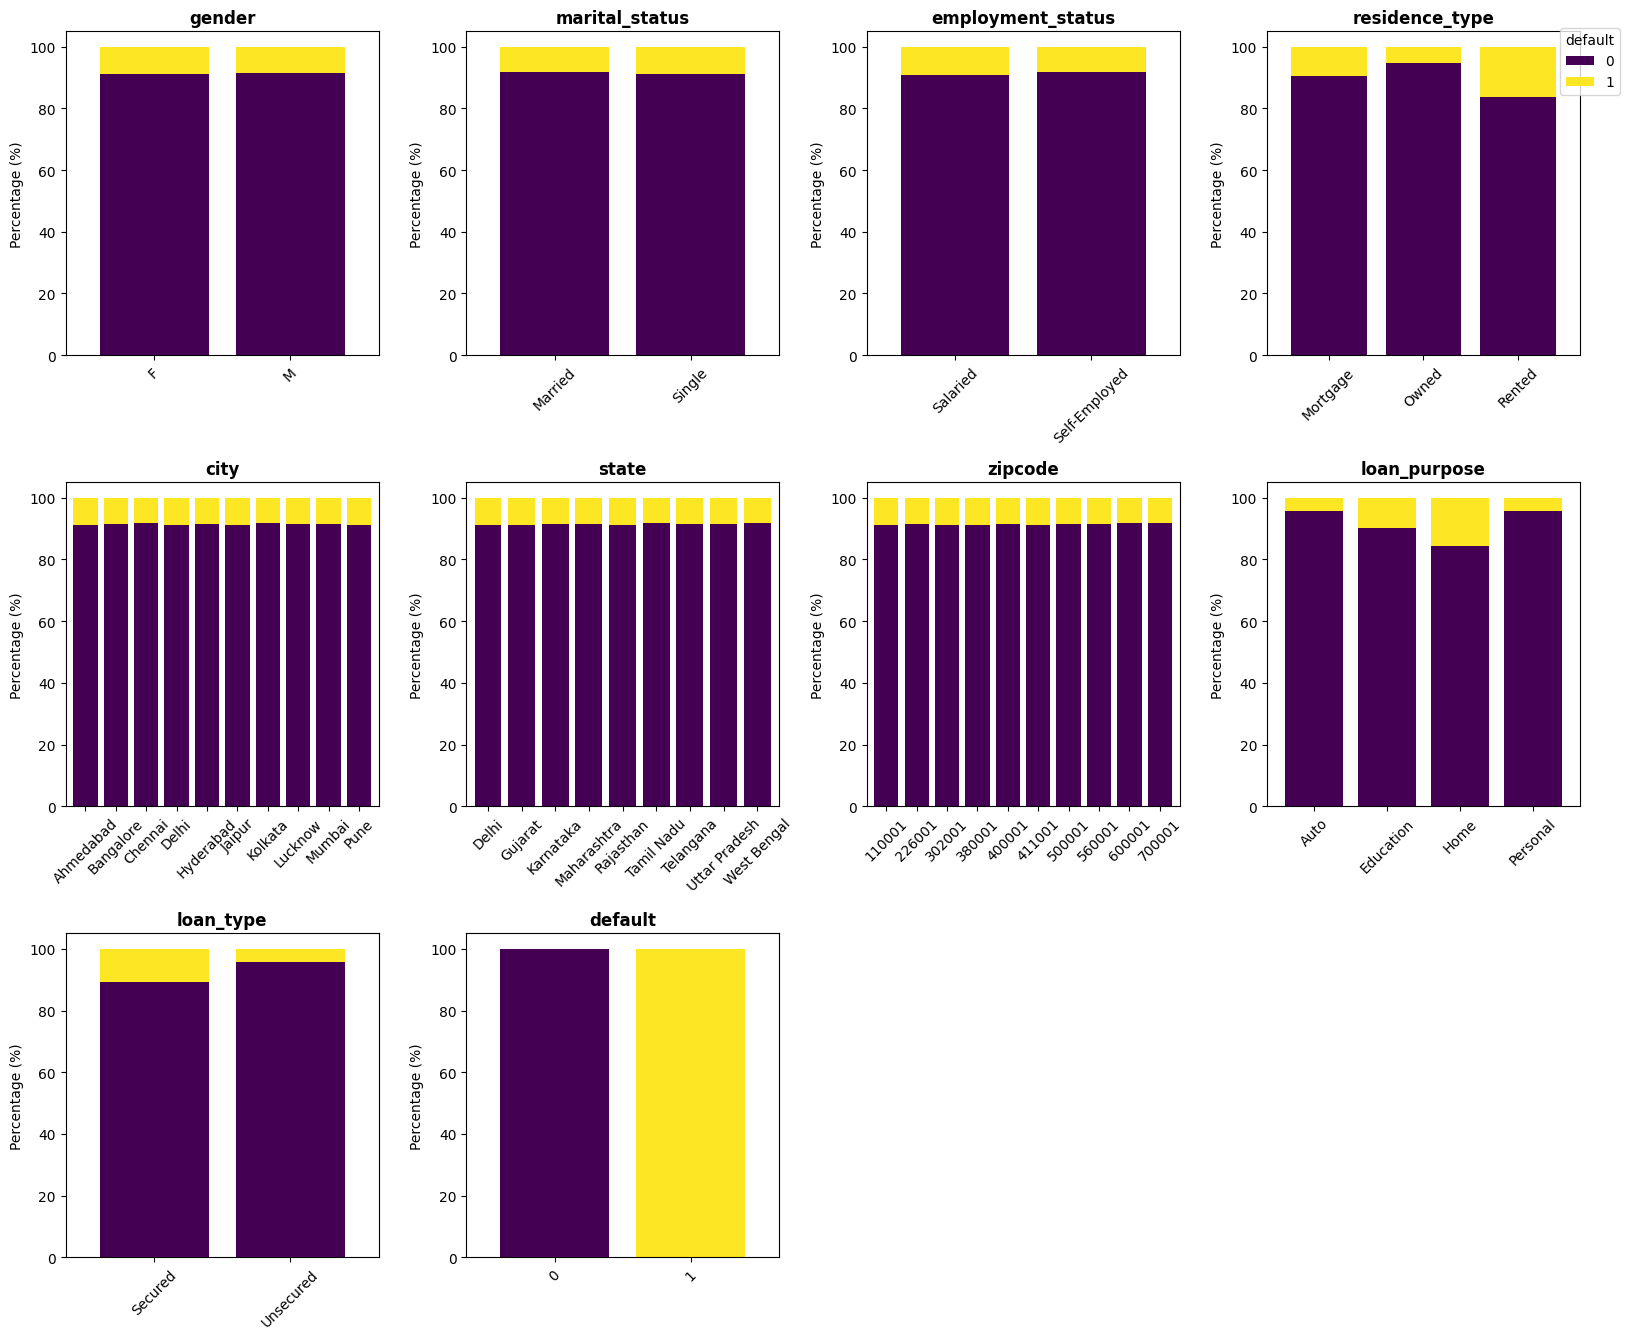

In [368]:

# Target column to stack by
target_col = "default"  # Replace with your categorical target column

n_cols = 4
n_plots = len(columns_categorical)
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for idx, col in enumerate(columns_categorical):
    # Compute cross-tabulation (normalize='index' for 100% stacked proportions)
    # Remove normalize='index' if you prefer raw frequencies
    ct = pd.crosstab(df_train_1[col], df_train_1[target_col], normalize="index") * 100

    # Plot stacked bar directly onto the subplot axis
    ct.plot(kind="bar", stacked=True, ax=axes[idx], colormap="viridis", width=0.8)

    axes[idx].set_title(col, fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("Percentage (%)")
    axes[idx].tick_params(axis="x", rotation=45)

    # Hide individual subplot legends to keep the layout clean
    axes[idx].get_legend().remove()

# Add a single unified legend for the target variable outside the grid
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title=target_col,
    loc="upper right",
    bbox_to_anchor=(1.02, 0.98),
)

# Remove unused axes
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

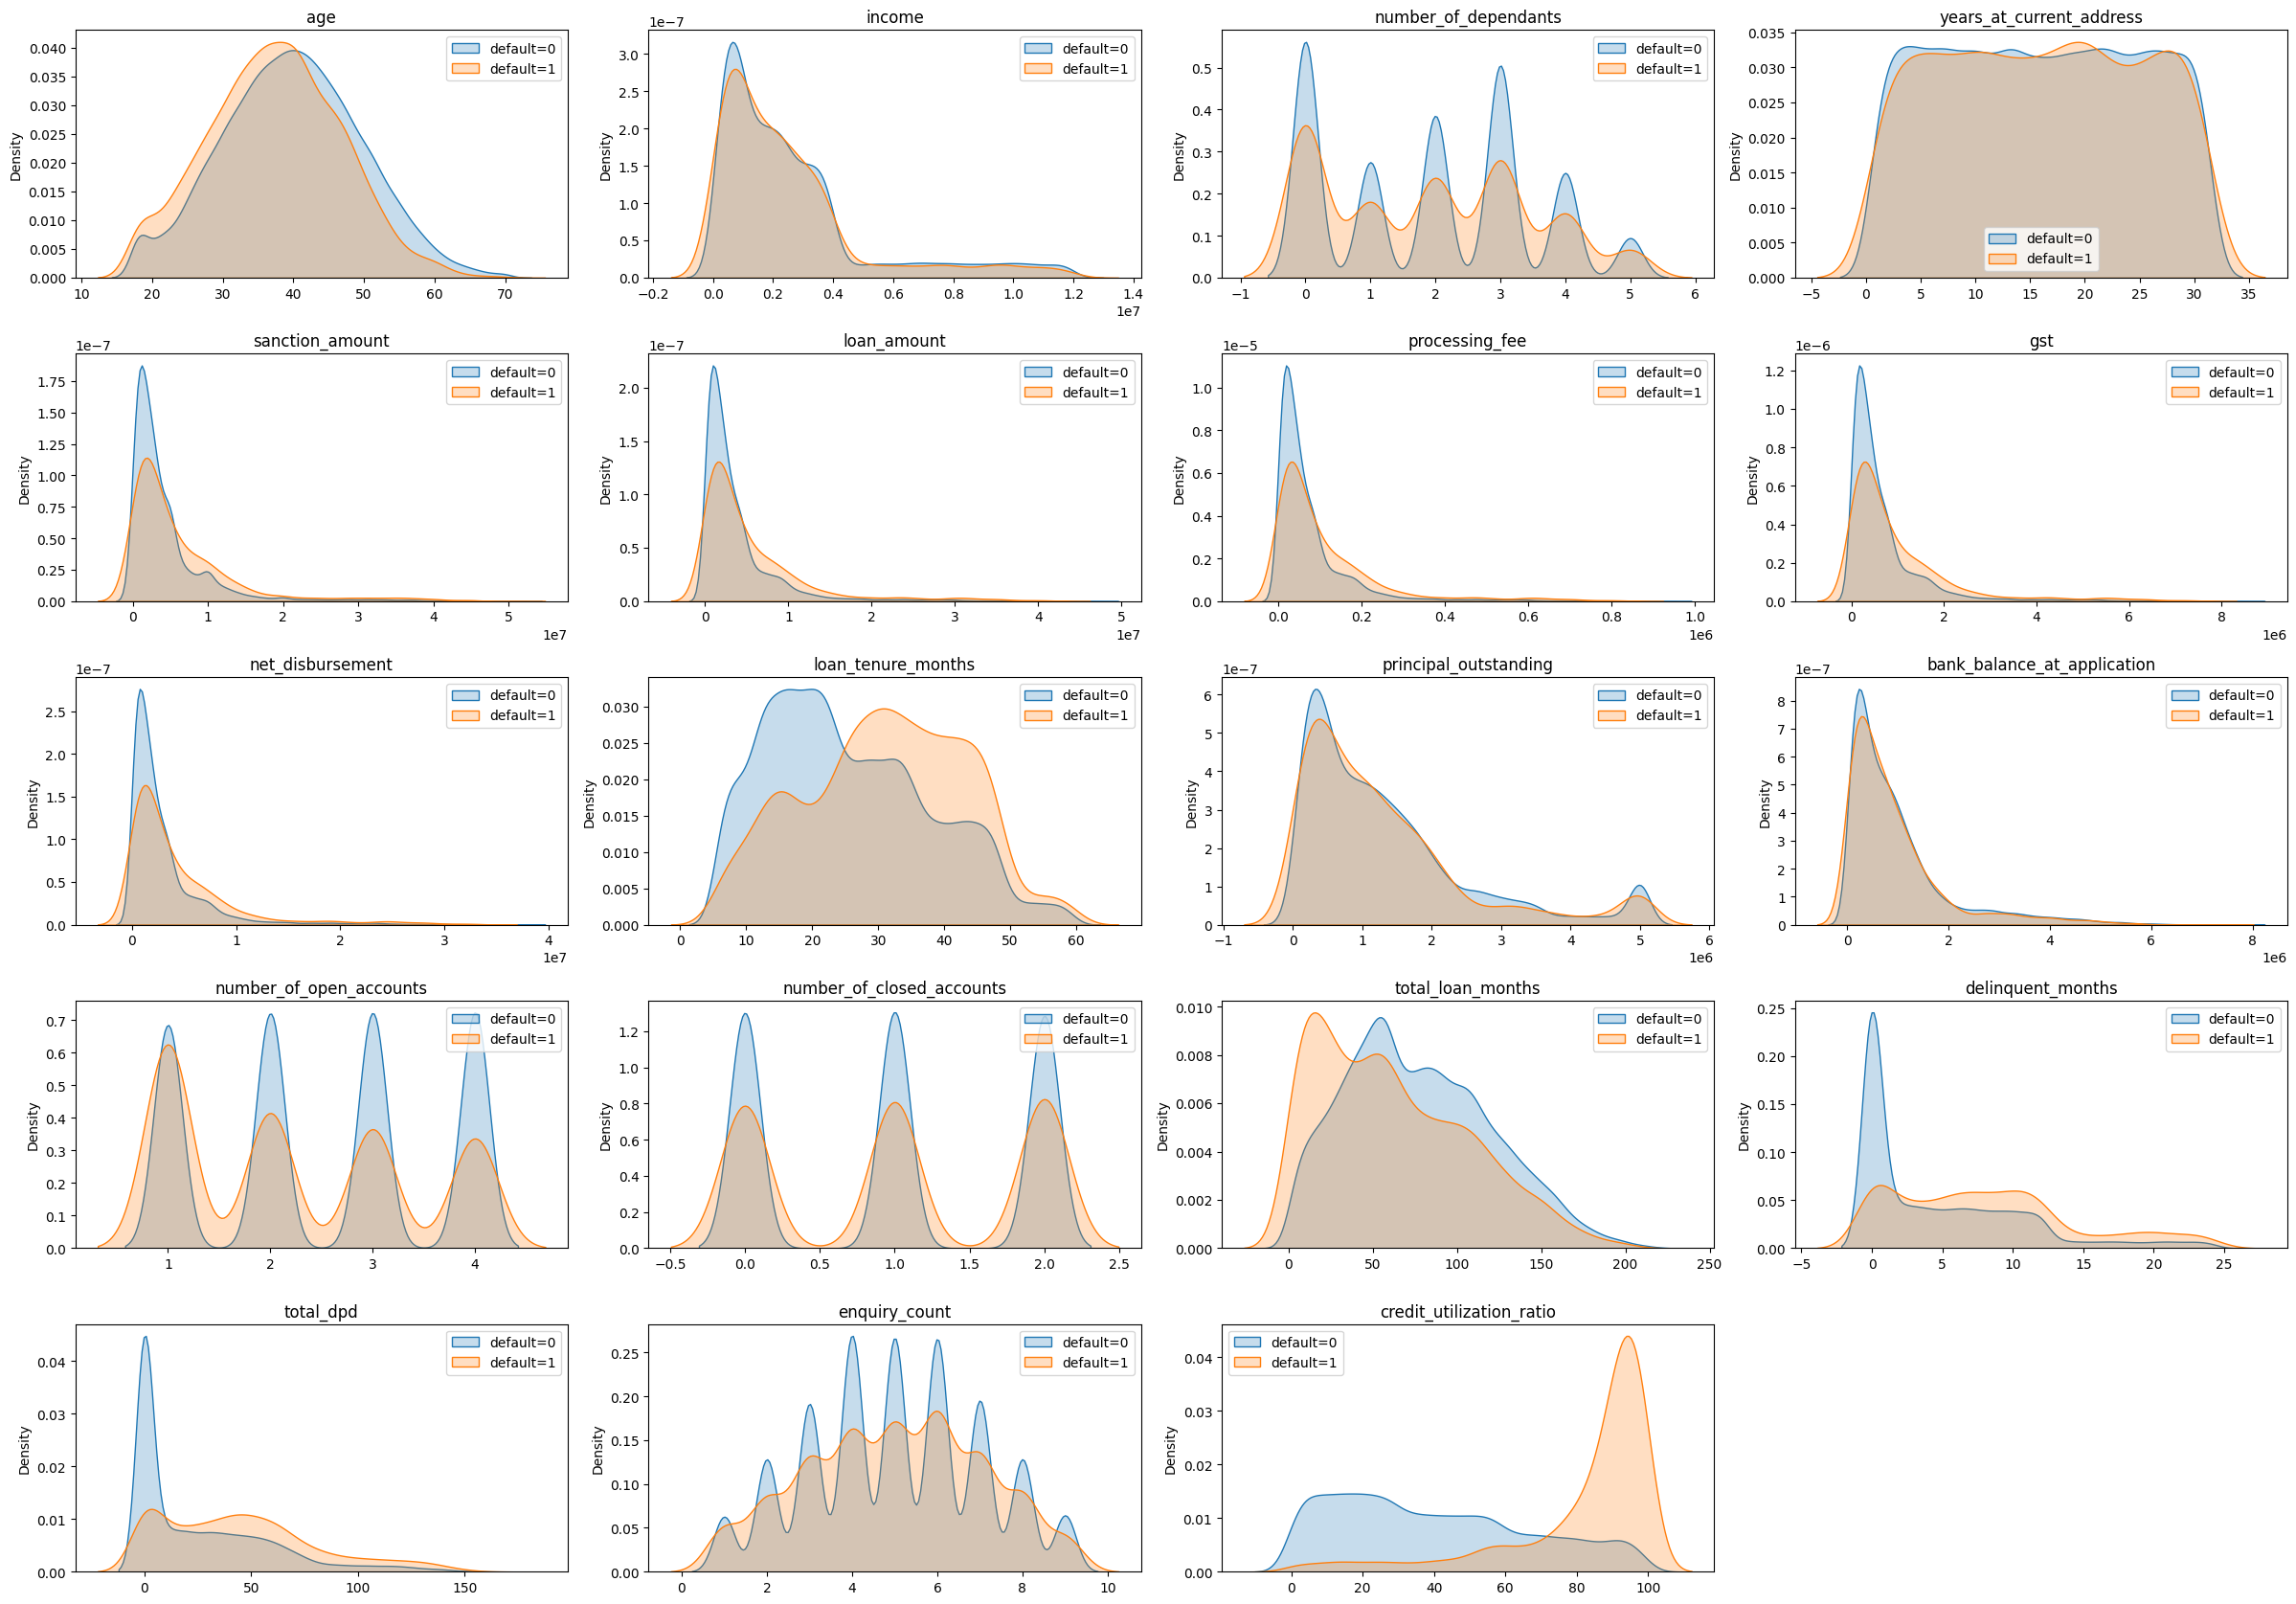

In [369]:
plt.figure(figsize=(24, 20))  # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1)  # 1 row, 4 columns, ith subplot
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.title(col)
    plt.xlabel('')
    plt.legend()


plt.tight_layout()
plt.show()

## 5. Domain-Driven Feature Engineering
Creating standardized financial risk ratios that capture borrower debt burden, repayment track record, delinquency severity, and credit utilization intensity:

1. **Loan-to-Income (LTI) Ratio**:
   $$\text{LTI} = \frac{\text{Loan Amount}}{\text{Annual Income}}$$
   Measures leverage and debt absorption capacity.
2. **Delinquency Ratio**:
   $$\text{Delinquency Ratio} = \frac{\text{Delinquent Months}}{\text{Total Loan Months}}$$
   Proportion of the borrower's total borrowing history spent in delinquency.
3. **Average DPD per Delinquency**:
   $$\text{Avg DPD} = \frac{\text{Total Days Past Due (DPD)}}{\text{Delinquent Months}}$$
   Measures default depth / delinquency severity when payments are missed.
4. **Credit Utilization per Income**:
   $$\text{Credit Utilization per LTI} = \frac{\text{Credit Utilization Ratio}}{\text{Loan-to-Income Ratio}}$$
   Cross-analyzes credit card limit utilization against leverage.

In [370]:
df_train_1['loan_to_income'] = (df_train_1['loan_amount'] / df_train_1['income']).round(2)
df_train_1['loan_to_income'].describe()

count   34988.00
mean        1.55
std         0.97
min         0.30
25%         0.77
50%         1.16
75%         2.45
max         4.57
Name: loan_to_income, dtype: float64

In [371]:
df_test['loan_to_income'] = (df_test['loan_amount'] / df_test['income']).round(2)

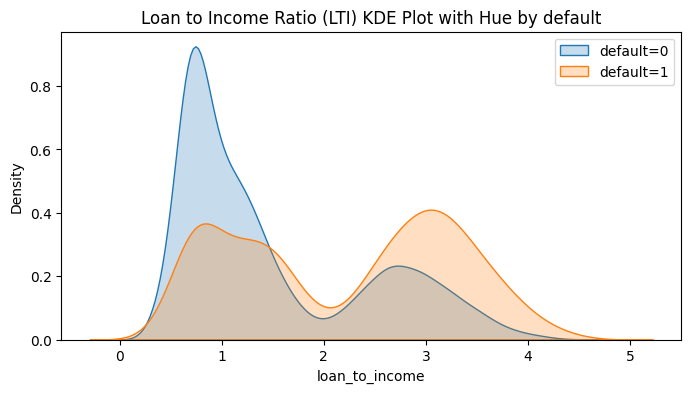

In [372]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['loan_to_income'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['loan_to_income'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"Loan to Income Ratio (LTI) KDE Plot with Hue by default")
plt.legend()
plt.show()

In [373]:
df_train_1['delinquency_ratio'] = (df_train_1.delinquent_months / df_train_1.total_loan_months).round(2)
df_test['delinquency_ratio'] = (df_test.delinquent_months / df_test.total_loan_months).round(2)

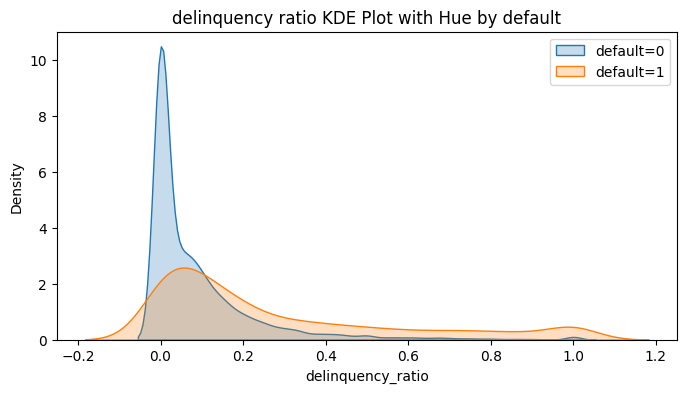

In [374]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['delinquency_ratio'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['delinquency_ratio'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"delinquency ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

In [375]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
    df_train_1.delinquent_months != 0,
    (df_train_1.total_dpd / df_train_1.delinquent_months).round(2),
    0
)
df_test['avg_dpd_per_delinquency'] = np.where(
    df_test.delinquent_months != 0,
    (df_test.total_dpd / df_test.delinquent_months).round(2),
    0
)

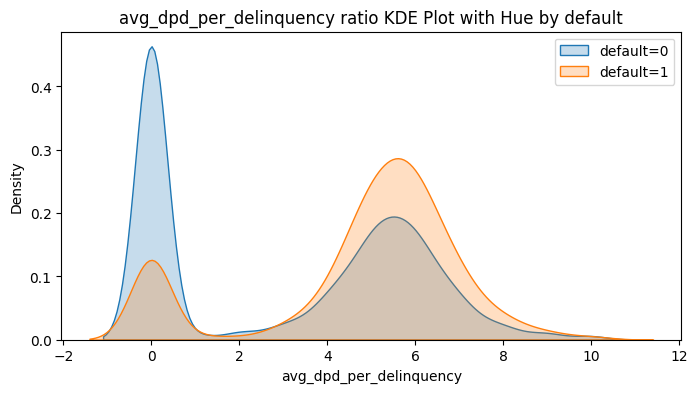

In [376]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['avg_dpd_per_delinquency'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['avg_dpd_per_delinquency'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"avg_dpd_per_delinquency ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

In [377]:
df_train_1['credit_utilization_per_income'] = np.where(
    df_train_1['loan_to_income'] != 0,
    (df_train_1['credit_utilization_ratio'] / df_train_1['loan_to_income']).round(1),
    0
)

df_test['credit_utilization_per_income'] = np.where(
    df_test['loan_to_income'] != 0,
    (df_test['credit_utilization_ratio'] / df_test['loan_to_income']).round(1),
    0
)

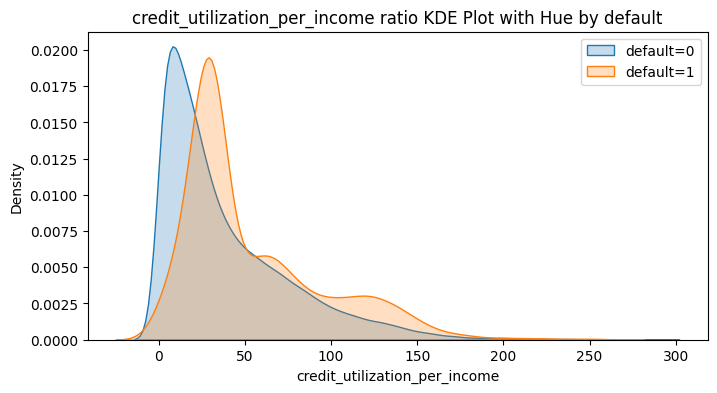

In [378]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['credit_utilization_per_income'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['credit_utilization_per_income'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"credit_utilization_per_income ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

In [379]:
df_train_1.columns

Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'],
      dtype='object')

In [380]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id'],axis="columns")
df_test = df_test.drop(['cust_id', 'loan_id'],axis="columns")

### Dropping Redundant Raw Columns
Removing the raw inputs whose predictive signal has been captured by the engineered ratios (`loan_amount`, `income`, `total_loan_months`, `delinquent_months`, `total_dpd`, `disbursal_date`, `installment_start_dt`).

In [381]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis="columns")
df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis="columns")
df_train_3.columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_purpose',
       'loan_type', 'sanction_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'],
      dtype='object')

## 6. Feature Scaling & Multicollinearity Analysis (VIF)

### 6.1 Continuous Feature Scaling (`MinMaxScaler`)
Applying `MinMaxScaler` on numerical features to rescale them between 0 and 1, ensuring distance and gradient calculations are not dominated by features with large absolute scales.

In [382]:
cols_to_scale = df_train_3.select_dtypes(exclude='object').columns.drop(['zipcode','default'])
cols_to_scale

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'sanction_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [383]:
X_train = df_train_3.drop('default', axis=1)
y_train = df_train_3['default']

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00
mean,0.50,0.50,0.50,0.44,0.42,0.39,0.50,418908.03,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.29,0.10,0.33,0.14
std,0.37,0.41,0.25,0.30,0.19,0.31,0.30,168898.77,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,110001.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.38,0.18,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.11,0.00,0.00,0.04
50%,0.33,0.50,0.50,0.39,0.42,0.40,0.50,400001.00,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.20,0.04,0.43,0.10
75%,0.67,1.00,0.62,0.68,0.54,0.60,0.77,560001.00,0.10,0.10,0.10,0.10,0.55,0.35,0.16,0.50,0.13,0.58,0.20
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,700001.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [384]:
X_test = df_test.drop('default', axis='columns')
y_test = df_test['default']

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00
mean,0.50,0.50,0.50,0.44,0.41,0.39,0.50,419538.37,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.29,0.10,0.33,0.14
std,0.37,0.41,0.25,0.30,0.19,0.31,0.30,169182.49,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,110001.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.38,0.18,0.29,0.00,0.27,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.11,0.00,0.00,0.04
50%,0.67,0.50,0.50,0.39,0.40,0.40,0.50,400001.00,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.20,0.04,0.43,0.10
75%,1.00,1.00,0.75,0.68,0.54,0.60,0.77,560001.00,0.10,0.10,0.10,0.10,0.55,0.35,0.16,0.50,0.13,0.58,0.20
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,700001.00,0.96,1.00,1.00,1.00,1.00,1.00,0.88,1.00,1.00,1.00,1.01


### 6.2 Variance Inflation Factor (VIF) Multicollinearity Check
Multicollinearity distorts regression coefficients and inflates variance. We compute VIF for each continuous feature:
$$VIF_i = \frac{1}{1 - R_i^2}$$
Features with severe collinearity ($VIF > 5$) are evaluated and iteratively eliminated.

In [385]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i,standardize=False) for i in range(data.shape[1])]
    return vif_df

In [386]:
calculate_vif(X_train[cols_to_scale])

C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\744348630.py:6: UserWarning: The design matrix is poorly conditioned (condition number=2.20e+17). VIF calculations may be numerically unstable.
  vif_df['VIF'] = [variance_inflation_factor(data.values,i,standardize=False) for i in range(data.shape[1])]
c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix 

,Column,VIF
0,number_of_open_accounts,4.36
1,number_of_closed_accounts,2.35
2,enquiry_count,6.38
3,credit_utilization_ratio,10.41
4,age,5.84
5,number_of_dependants,2.72
6,years_at_current_address,3.38
7,sanction_amount,102.11
8,processing_fee,1000799917193443.50
9,gst,1000799917193443.50


In [387]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement','principal_outstanding']


X_train_1 = X_train.drop(features_to_drop_vif, axis='columns')
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'zipcode', 'loan_tenure_months',
       'bank_balance_at_application', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [388]:
calculate_vif(X_train_1[numeric_columns])

C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\744348630.py:6: UserWarning: The design matrix is poorly conditioned (condition number=7.56e+06). VIF calculations may be numerically unstable.
  vif_df['VIF'] = [variance_inflation_factor(data.values,i,standardize=False) for i in range(data.shape[1])]


,Column,VIF
0,number_of_open_accounts,4.33
1,number_of_closed_accounts,2.37
2,enquiry_count,6.46
3,credit_utilization_ratio,10.11
4,age,5.71
5,number_of_dependants,2.73
6,years_at_current_address,3.46
7,zipcode,5.69
8,loan_tenure_months,6.17
9,bank_balance_at_application,1.89


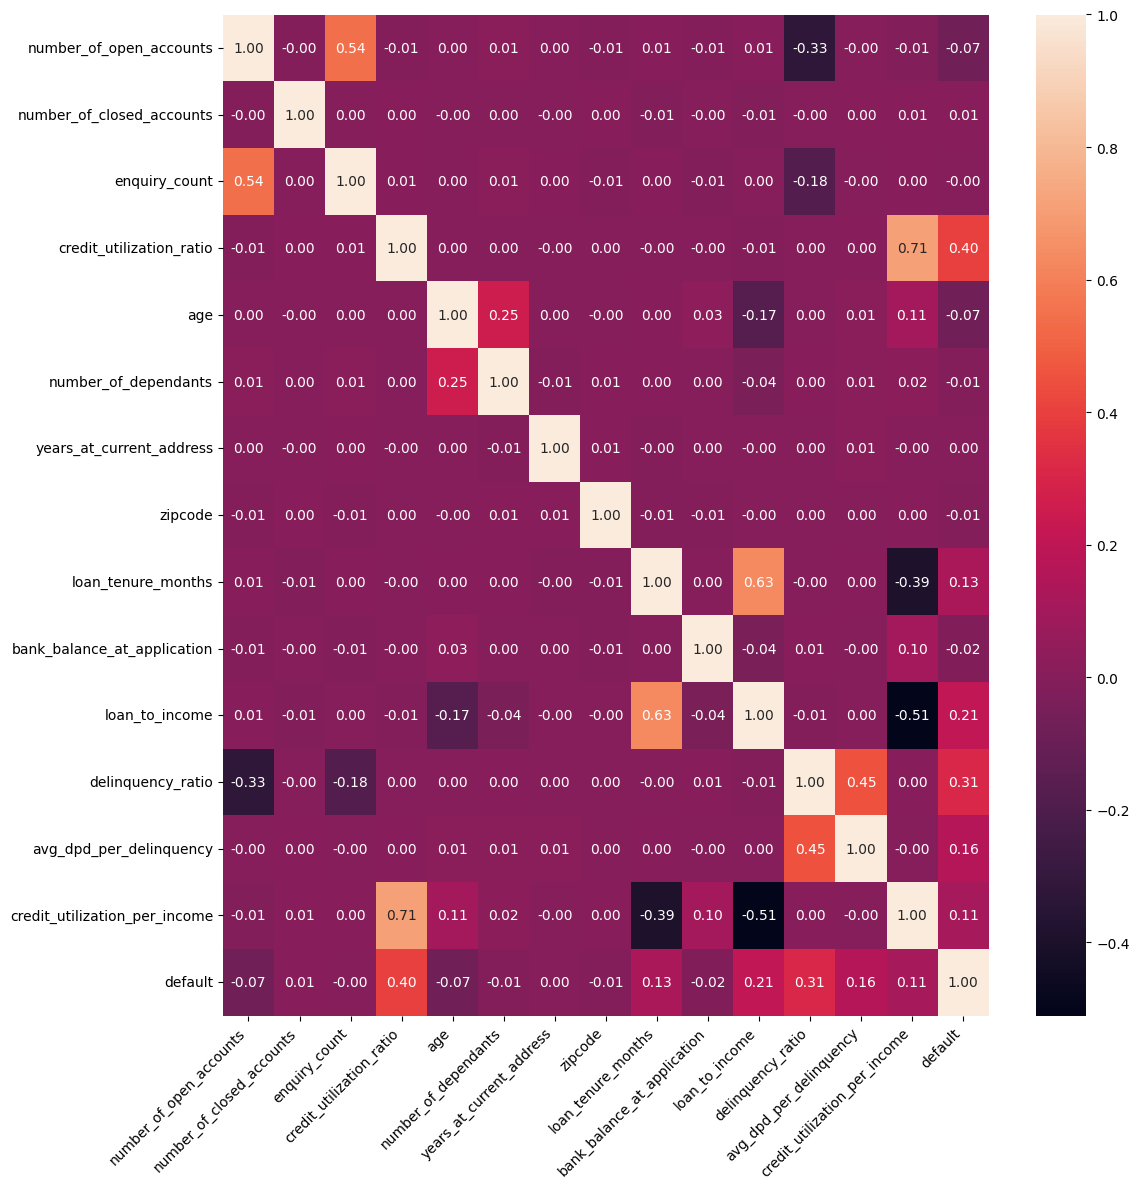

In [389]:
plt.figure(figsize=(12,12))
cm = df_train_3[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [390]:
X_train_1.head()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,number_of_dependants,residence_type,...,state,zipcode,loan_purpose,loan_type,loan_tenure_months,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
38094,1.00,0.00,1.00,0.42,0.50,F,Single,Self-Employed,0.00,Mortgage,...,Tamil Nadu,600001,Home,Secured,0.58,0.01,0.56,0.00,0.00,0.05
40624,0.33,1.00,0.75,0.08,0.40,M,Married,Self-Employed,0.80,Owned,...,Gujarat,380001,Personal,Unsecured,0.28,0.48,0.04,0.00,0.00,0.06
49425,1.00,0.50,0.75,0.27,0.37,F,Married,Self-Employed,0.80,Owned,...,Maharashtra,411001,Auto,Secured,0.40,0.23,0.19,0.00,0.00,0.08
35734,1.00,0.00,0.88,0.78,0.71,M,Single,Salaried,0.00,Owned,...,West Bengal,700001,Personal,Unsecured,0.08,0.03,0.06,0.08,0.64,0.48
41708,0.67,0.50,0.62,0.86,0.54,M,Married,Self-Employed,0.80,Owned,...,Maharashtra,400001,Auto,Secured,0.42,0.02,0.21,0.00,0.00,0.25


## 7. Weight of Evidence (WoE) & Information Value (IV) Selection
In professional credit scorecard engineering (Basel II/III compliance), **Weight of Evidence (WoE)** and **Information Value (IV)** are the industry standard for feature screening:

$$WoE_i = \ln\left(\frac{\% \text{ Non-Defaults}_i}{\% \text{ Defaults}_i}\right)$$
$$IV = \sum_{i=1}^k \left(\% \text{ Non-Defaults}_i - \% \text{ Defaults}_i\right) \times WoE_i$$

### Standard IV Interpretation:
* **$< 0.02$**: Not predictive (drop)
* **$0.02 - 0.10$**: Weak predictive power
* **$0.10 - 0.30$**: Medium predictive power
* **$0.30 - 0.50$**: Strong predictive power
* **$> 0.50$**: Suspicious / Over-predictive

In [391]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count','sum'])
    grouped = grouped.rename(columns={'count': 'total', 'sum': 'good'})
    grouped['bad']=grouped['total']-grouped['good']

    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    grouped['good_pct'] = grouped['good'] / total_good
    grouped['bad_pct'] = grouped['bad'] / total_bad
    grouped['woe'] = np.log(grouped['good_pct']/ grouped['bad_pct'])
    grouped['iv'] = (grouped['good_pct'] -grouped['bad_pct'])*grouped['woe']

    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)

    total_iv = grouped['iv'].sum()

    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train],axis=1), 'loan_purpose', 'default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,6925,299,6626,0.10,0.21,-0.73,0.08
Education,5265,519,4746,0.17,0.15,0.16,0.00
Home,10510,1635,8875,0.55,0.28,0.68,0.18
Personal,12288,542,11746,0.18,0.37,-0.71,0.13


In [392]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == 'object':
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train],axis=1), feature, 'default' )
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train],axis=1), feature, 'default' )
    iv_values[feature] = iv

iv_values

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


{'number_of_open_accounts': np.float64(0.07325581356695361),
 'number_of_closed_accounts': np.float64(0.0005687210026574292),
 'enquiry_count': np.float64(0.005456328413885875),
 'credit_utilization_ratio': np.float64(2.3927055862612425),
 'age': np.float64(0.07694701309826596),
 'gender': np.float64(0.0005709662521100581),
 'marital_status': np.float64(0.002319164107345311),
 'employment_status': np.float64(0.002438998747887179),
 'number_of_dependants': np.float64(0.004617166112341162),
 'residence_type': np.float64(0.25864377110359527),
 'years_at_current_address': np.float64(0.0008423568825644974),
 'city': np.float64(0.0009145141559576685),
 'state': np.float64(0.0008165745047632677),
 'zipcode': np.float64(0.0007260516605229381),
 'loan_purpose': np.float64(0.39563682588883553),
 'loan_type': np.float64(0.17971560979330453),
 'loan_tenure_months': np.float64(0.23560718802185557),
 'bank_balance_at_application': np.float64(0.005901492342451912),
 'loan_to_income': np.float64(0.495

In [393]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
3,credit_utilization_ratio,2.393
19,delinquency_ratio,0.683
18,loan_to_income,0.496
20,avg_dpd_per_delinquency,0.423
14,loan_purpose,0.396
9,residence_type,0.259
16,loan_tenure_months,0.236
21,credit_utilization_per_income,0.215
15,loan_type,0.180
4,age,0.077


In [394]:
# select features that has IV > 0.02
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['number_of_open_accounts',
 'credit_utilization_ratio',
 'age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency',
 'credit_utilization_per_income']

In [395]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [396]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)


In [397]:
y_train.value_counts()

default
0    31993
1     2995
Name: count, dtype: int64

## 8. Model Development & Iterative Experiments

### Experiment 1: Baseline Modeling (No Class Imbalance Treatment)
* **Models**: Logistic Regression, Random Forest, XGBoost
* **Condition**: Raw imbalanced class distribution (~91.4% Non-Default, ~8.6% Default).
* **Observation**: High overall accuracy but poor recall on the minority default class.

In [398]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.84      0.69      0.76      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.84      0.87     14997
weighted avg       0.96      0.96      0.96     14997



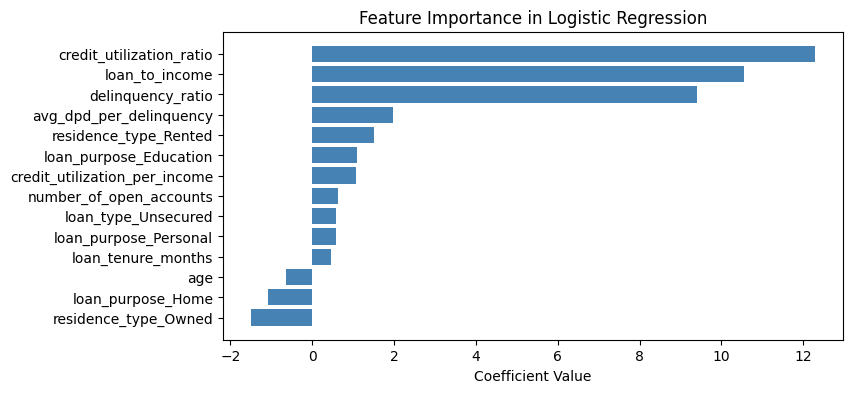

In [399]:
feature_importance = model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

In [400]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.84      0.71      0.76      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.85      0.87     14997
weighted avg       0.96      0.96      0.96     14997



In [401]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     13695
           1       0.82      0.74      0.78      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.86      0.88     14997
weighted avg       0.96      0.96      0.96     14997



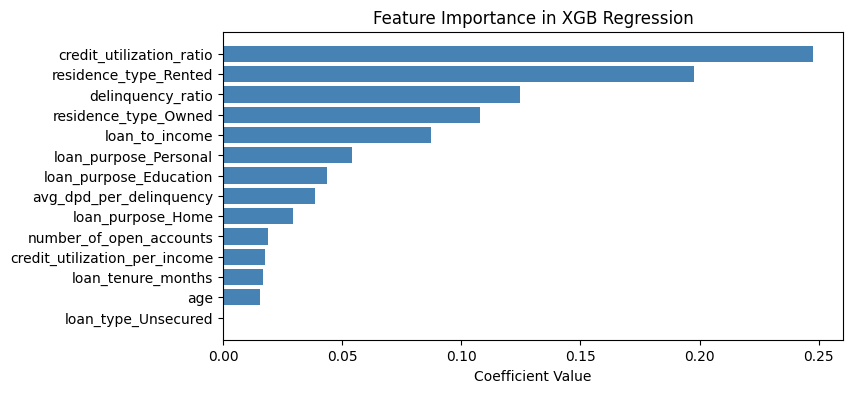

In [402]:
feature_importance = model.feature_importances_

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in XGB Regression')
plt.show()

In [403]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': np.logspace(-4, 4, 20),  # Logarithmically spaced values from 10^-4 to 10^4
    'solver': ['lbfgs', 'saga', 'liblinear', 'newton-cg']   # Algorithm to use in the optimization problem
}

# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=10000)  # Increased max_iter for convergence

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=50,  # Number of parameter settings that are sampled
    scoring='f1',
    cv=3,  # 5-fold cross-validation
    verbose=2,
    random_state=42,  # Set a random state for reproducibility
    n_jobs=-1  # Use all available cores
)

# Fit the RandomizedSearchCV to the training data
random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'solver': 'lbfgs', 'C': np.float64(78.47599703514607)}
Best Score: 0.7606019808030418
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.83      0.71      0.77      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.85      0.87     14997
weighted avg       0.96      0.96      0.96     14997



In [404]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight': [1, 2, 3, 5, 7, 10],
    'reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],  # L1 regularization term
    'reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]  # L2 regularization term
}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_dist, n_iter=100,
                                   scoring='f1', cv=3, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.8, 'scale_pos_weight': 2, 'reg_lambda': 1.0, 'reg_alpha': 5.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.9}
Best Score: 0.7917420500357467
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     13695
           1       0.78      0.82      0.80      1302

    accuracy                           0.96     14997
   macro avg       0.88      0.90      0.89     14997
weighted avg       0.97      0.96      0.96     14997



### Experiment 2: Handling Imbalance via Random Under-Sampling
Balancing class frequencies by randomly under-sampling the majority non-default class down to the count of default cases.

In [405]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train_encoded, y_train)
y_train_res.value_counts()

default
0    2995
1    2995
Name: count, dtype: int64

In [406]:
model = LogisticRegression()
model.fit(X_train_res, y_train_res)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     13695
           1       0.51      0.95      0.67      1302

    accuracy                           0.92     14997
   macro avg       0.75      0.93      0.81     14997
weighted avg       0.95      0.92      0.93     14997



In [407]:
model = XGBClassifier(**random_search.best_params_)
model.fit(X_train_res, y_train_res)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     13695
           1       0.50      0.99      0.67      1302

    accuracy                           0.91     14997
   macro avg       0.75      0.95      0.81     14997
weighted avg       0.96      0.91      0.93     14997



### Experiment 3: Advanced Resampling (SMOTE-Tomek) & Optuna Hyperparameter Optimization
* **Resampling**: `SMOTETomek` synthesizes minority default examples while removing borderline noisy samples (Tomek links).
* **Hyperparameter Optimization**: Bayesian optimization via **Optuna** to maximize Macro F1-score for Logistic Regression.

In [408]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    31927
1    31927
Name: count, dtype: int64

In [409]:
model = LogisticRegression()
model.fit(X_train_smt, y_train_smt)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.56      0.95      0.70      1302

    accuracy                           0.93     14997
   macro avg       0.78      0.94      0.83     14997
weighted avg       0.96      0.93      0.94     14997



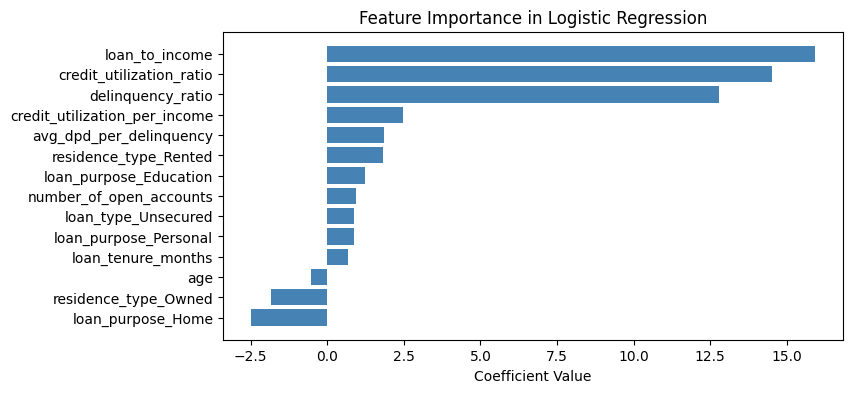

In [410]:
feature_importance = model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

In [411]:
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

In [412]:
# Define the objective function for Optuna
def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),  # Logarithmically spaced values
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),  # Solvers
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),  # Logarithmically spaced values for tolerance
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])  # Class weights
    }

    model = LogisticRegression(**param, max_iter=10000)

    # Calculate the cross-validated f1_score
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(objective, n_trials=50)

[I 2026-10-26 19:07:39,492] A new study created in memory with name: no-name-2f4620ab-822e-4020-9e0d-a6c22d397894
[I 2026-10-26 19:07:39,622] Trial 0 finished with value: 0.9251922985380318 and parameters: {'C': 3355.876223082484, 'solver': 'lbfgs', 'tol': 0.0064852977058968515, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9251922985380318.
[I 2026-10-26 19:07:39,810] Trial 1 finished with value: 0.9454566382621779 and parameters: {'C': 146.94544555286586, 'solver': 'saga', 'tol': 0.005477021277485919, 'class_weight': None}. Best is trial 1 with value: 0.9454566382621779.
[I 2026-10-26 19:07:40,053] Trial 2 finished with value: 0.9454717939038461 and parameters: {'C': 6.2951179908568475, 'solver': 'newton-cg', 'tol': 2.93836182689696e-06, 'class_weight': None}. Best is trial 2 with value: 0.9454717939038461.
[I 2026-10-26 19:07:40,150] Trial 3 finished with value: 0.9144893638812398 and parameters: {'C': 5448.826420590898, 'solver': 'lbfgs', 'tol': 0.011024927313489608, '

In [413]:
print('Best trial:')
trial = study_logistic.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.9456687867192587
  Params: 
    C: 287.6135123982441
    solver: newton-cg
    tol: 0.0009852486249427351
    class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.55      0.95      0.69      1302

    accuracy                           0.93     14997
   macro avg       0.77      0.94      0.83     14997
weighted avg       0.96      0.93      0.94     14997



### Experiment 4: XGBoost Optimization with SMOTE-Tomek
Tuning tree depth, learning rate, regularization (L1/L2), and subsample rates using Optuna on SMOTE-Tomek balanced data.

In [414]:
# Define the objective function for Optuna
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model = XGBClassifier(**param)

    # Calculate the cross-validated f1_score
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective, n_trials=50)

[I 2026-10-26 19:07:49,841] A new study created in memory with name: no-name-9a7e94b0-3bc4-4c6d-a02c-e4c1dd58d4d6
[I 2026-10-26 19:07:50,404] Trial 0 finished with value: 0.9647769562797733 and parameters: {'lambda': 1.6238567051513706, 'alpha': 0.006910255400108255, 'subsample': 0.81104398182018, 'colsample_bytree': 0.7348422224370748, 'max_depth': 5, 'eta': 0.28148558728898404, 'gamma': 2.2637803496937736, 'scale_pos_weight': 8.053526759917094, 'min_child_weight': 8, 'max_delta_step': 4}. Best is trial 0 with value: 0.9647769562797733.
[I 2026-10-26 19:07:51,179] Trial 1 finished with value: 0.9413136167221628 and parameters: {'lambda': 0.045350327343733246, 'alpha': 0.005042129642517065, 'subsample': 0.9253263832452463, 'colsample_bytree': 0.4377073852248511, 'max_depth': 10, 'eta': 0.04786773157692183, 'gamma': 8.443590350333272, 'scale_pos_weight': 5.775941329798446, 'min_child_weight': 5, 'max_delta_step': 7}. Best is trial 0 with value: 0.9647769562797733.
[I 2026-10-26 19:07:51

In [415]:
print('Best trial:')
trial = study_xgb.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_params = study_xgb.best_params
best_model_xgb = XGBClassifier(**best_params)
best_model_xgb.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.9737291880159882
  Params: 
    lambda: 0.028469286461291862
    alpha: 0.03774467006285704
    subsample: 0.5064042937783505
    colsample_bytree: 0.6334303068849201
    max_depth: 8
    eta: 0.2150734735228423
    gamma: 1.5637108501390418
    scale_pos_weight: 2.841593843314928
    min_child_weight: 2
    max_delta_step: 4
              precision    recall  f1-score   support

           0       0.99      0.96      0.97     13695
           1       0.69      0.88      0.77      1302

    accuracy                           0.95     14997
   macro avg       0.84      0.92      0.87     14997
weighted avg       0.96      0.95      0.96     14997



In [416]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.55      0.95      0.69      1302

    accuracy                           0.93     14997
   macro avg       0.77      0.94      0.83     14997
weighted avg       0.96      0.93      0.94     14997



## 9. Comprehensive Model Evaluation & Discrimination Metrics
Evaluating credit risk discrimination power using:
* **Receiver Operating Characteristic (ROC) & AUC**
* **Gini Coefficient**:
  $$\text{Gini} = 2 \times \text{AUC} - 1$$
  A standard banking benchmark where Gini $> 0.60$ demonstrates strong model discrimination.

In [417]:
from sklearn.metrics import roc_curve

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

fpr[:5], tpr[:5], thresholds[:5]

(array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 7.30193501e-05,
        7.30193501e-05]),
 array([0.        , 0.00076805, 0.1858679 , 0.1858679 , 0.21121352]),
 array([       inf, 0.9999994 , 0.99774697, 0.99767614, 0.99708482]))

In [418]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.9831393721794033

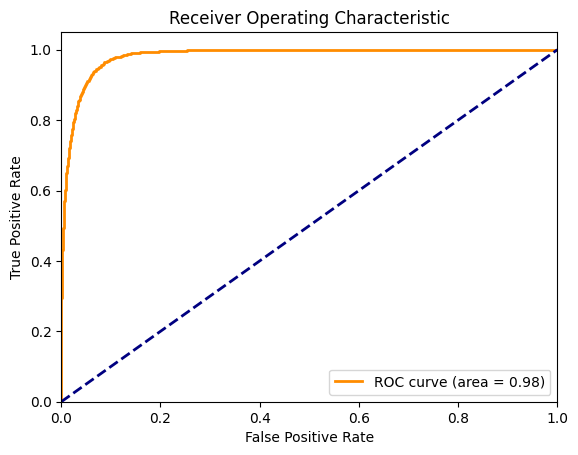

In [419]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [420]:
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval = pd.DataFrame({
    'Default Truth': y_test,
    'Default Probability': probabilities
})

df_eval['Decile'] = pd.qcut(df_eval['Default Probability'], 10, labels=False, duplicates='drop')

df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),
}))
df_decile.reset_index(inplace=True)

df_decile['Event Rate'] = df_decile['Events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile['Non-event Rate'] = df_decile['Non-events']*100 / (df_decile['Events']+df_decile['Non-events'])

df_decile = df_decile.sort_values(by='Decile', ascending=False).reset_index(drop=True)

df_decile['Cum Events'] =  df_decile['Events'].cumsum()
df_decile['Cum Non-events'] =  df_decile['Non-events'].cumsum()

df_decile['Cum Event Rate'] = df_decile['Cum Events'] * 100 / df_decile['Events'].sum()
df_decile['Cum Non-event Rate'] = df_decile['Cum Non-events']*100 / df_decile['Non-events'].sum()

df_decile['KS'] = abs(df_decile['Cum Event Rate'] - df_decile['Cum Non-event Rate'])
df_decile


C:\Users\Admin\AppData\Local\Temp\ipykernel_11948\3782367545.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({


,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
0,9,0.797,1.000,1080.000,420.000,72.000,28.000,1080.000,420.000,82.949,3.067,79.882
1,8,0.260,0.797,201.000,1299.000,13.400,86.600,1281.000,1719.000,98.387,12.552,85.835
2,7,0.054,0.260,18.000,1481.000,1.201,98.799,1299.000,3200.000,99.770,23.366,76.403
3,6,0.011,0.054,2.000,1498.000,0.133,99.867,1301.000,4698.000,99.923,34.304,65.619
4,5,0.002,0.011,1.000,1498.000,0.067,99.933,1302.000,6196.000,100.000,45.243,54.757
5,4,0.001,0.002,0.000,1500.000,0.000,100.000,1302.000,7696.000,100.000,56.196,43.804
6,3,0.000,0.001,0.000,1500.000,0.000,100.000,1302.000,9196.000,100.000,67.149,32.851
7,2,0.000,0.000,0.000,1499.000,0.000,100.000,1302.000,10695.000,100.000,78.094,21.906
8,1,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,12195.000,100.000,89.047,10.953
9,0,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,13695.000,100.000,100.000,0.000


In [421]:
gini_coefficient = 2 * area - 1

print("AUC:", area)
print("Gini Coefficient:", gini_coefficient)

AUC: 0.9831393721794033
Gini Coefficient: 0.9662787443588066


## 10. Secondary Optimization: Bayesian Optimization & Grid Search
Benchmarking alternative hyperparameter tuning frameworks (BayesianOptimization and GridSearchCV) across cross-validation folds.

In [422]:
from bayes_opt import BayesianOptimization

In [423]:
# Define the function to optimize
def optimize_log_reg(C, max_iter):
    model = LogisticRegression(C=C, max_iter=int(max_iter), solver='liblinear')
    # Perform 5-fold cross-validation
    scores = cross_val_score(model, X_train_encoded, y_train, cv=5, scoring='roc_auc')
    # We want to maximize the AUC-ROC score
    return scores.mean()

In [424]:
param_bounds = {
    'C': (0.001, 10.0),
    'max_iter': (50, 500)
}

In [425]:
# Initialize the Bayesian optimizer
optimizer = BayesianOptimization(
    f=optimize_log_reg,
    pbounds=param_bounds,
    random_state=42
)

In [426]:
# Perform the optimization
optimizer.maximize(init_points=10, n_iter=50)

|   iter    |  target   |     C     | max_iter  |
-------------------------------------------------
| 1         | 0.9828915 | 3.7460266 | 477.82143 |
| 2         | 0.9829403 | 7.3202074 | 319.39631 |
| 3         | 0.9826945 | 1.5610303 | 120.19753 |
| 4         | 0.9820440 | 0.5817780 | 439.77926 |
| 5         | 0.9829314 | 6.0115490 | 368.63266 |
| 6         | 0.9803802 | 0.2068243 | 486.45943 |
| 7         | 0.9829497 | 8.3245939 | 145.55259 |
| 8         | 0.9827394 | 1.8190678 | 132.53202 |
| 9         | 0.9828627 | 3.0431181 | 286.14039 |
| 10        | 0.9829041 | 4.3200182 | 181.05311 |
| 11        | 0.9829449 | 7.8519744 | 118.46654 |
| 12        | 0.9829394 | 6.8724631 | 146.54472 |
| 13        | 0.9829364 | 6.5510892 | 471.05374 |
| 14        | 0.9829535 | 8.9537537 | 109.32958 |
| 15        | 0.9829330 | 6.1994577 | 309.76401 |
| 16        | 0.9829205 | 4.9508547 | 298.61350 |
| 17        | 0.9817540 | 0.4532525 | 360.00987 |
| 18        | 0.9829560 | 9.8676847 | 376.41198 |


In [427]:
# Extract the best parameters
best_params = optimizer.max['params']
best_params['max_iter'] = int(best_params['max_iter'])

In [428]:
# Train the final model with the best parameters
final_model = LogisticRegression(**best_params, solver='liblinear')
final_model.fit(X_train_encoded, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,np.float64(9.867684760525588)
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,376
,multi_class,'deprecated'


In [429]:
# Evaluate the final model on the test set
y_pred = final_model.predict(X_test_encoded)
y_prob = final_model.predict_proba(X_test_encoded)[:, 1]

In [430]:
# Print the classification report and AUC-ROC score
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.83      0.72      0.77      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.85      0.87     14997
weighted avg       0.96      0.96      0.96     14997



In [431]:
print("AUC-ROC Score:", roc_auc_score(y_test, y_pred))

AUC-ROC Score: 0.8505900434582907


In [432]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for XGBoost
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)


In [433]:
# Fit GridSearchCV
grid_search.fit(X_train_encoded, y_train)

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [19:09:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8, 0.9, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [50, 100, ...], ...}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [434]:
# Extract the best parameters
best_params = grid_search.best_params_
best_params

{'colsample_bytree': 0.9,
 'learning_rate': 0.1,
 'max_depth': 3,
 'n_estimators': 200,
 'subsample': 0.8}

In [435]:
# Train the final model with the best parameters
best_xgb_model = grid_search.best_estimator_
y_pred = best_xgb_model.predict(X_test_encoded)
y_prob = best_xgb_model.predict_proba(X_test_encoded)[:, 1]

In [436]:
# Evaluate the final model
roc_auc = roc_auc_score(y_test, y_prob)
roc_auc

0.9882782070889339

In [437]:
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.85      0.73      0.78      1302

    accuracy                           0.97     14997
   macro avg       0.91      0.86      0.88     14997
weighted avg       0.96      0.97      0.96     14997



## 11. Production Artifact Serialization
Saving the final optimized model object, fitted `MinMaxScaler`, scaling columns, and feature signatures into `artifacts/model.joblib` for consumption by the Streamlit user interface and prediction service.

In [438]:
from joblib import dump
model = {
    'model':best_model_logistic,
    'scaler':scaler,
    'cols_to_scale':scaler.feature_names_in_,
    'features':X_train_smt.columns
}

dump(model, 'artifacts/model.joblib')

['artifacts/model.joblib']